#  __Using <font color=blue><a href=https://mlbi-lab.net>SCODA</a></font> for Single-cell RNA-seq data analysis and mining__

- This Jupyter notebook provides example code for visualizing and mining the results processed by <a href=https://mlbi-lab.net>__SCODA__</a>, a single-cell RNA-seq data analysis pipeline developed by __MLBI Lab__.
- Data mining is conducted using the __SCODA-viz__ package and includes the following components:

<br>

1. <font color=blue>Review of cell type annotation results</font>
   - Preprocessing for visualization and generation of UMAP coordinates
   - Visualization of celltype marker expression patterns
   - Examination of cell type populations and identification of condition-specific features
2. <font color=blue>Review of CNV and tumor cell identification results</font>
   - Visualization of CNV patterns via heatmap
   - Tumor cell identification confirmed via UMAP projection
3. <font color=blue>Profiling of ligand–receptor interactions between cell types</font>
  - Structure and composition of CCI result data
  - Visualization using dot plots and circle plots
  - Statistical testing of condition-specific interactions and visualization via boxplots
4. <font color=blue>Differential expression analysis and marker/target discovery</font>
  - Structure of DEG result data
  - Inspection of DEG results
  - Marker/target discovery and visualization using dot plots
5. <font color=blue>Gene set analysis (GSA) and interpretation of enrichment results</font>
  - Structure of GSA/GSEA output data
  - Visualization of GSA/GSEA results using barplots
  - Visualization of GSA/GSEA results using dotplots

6. <font color=firebrick>Auxiliary analysis using cancer genomics big data</font> (e.g., METABRIC or TCGA data)
7. <font color=firebrick>Visualization of pathway-level changes using KEGG Pathview</font> (provided in a separate notebook using R)

<br>

__MLBI-lab, July 27, 2025__

contact: mlbi@mlbi-lab.com




## __1. Install required packages and import them__

In [ ]:
## 필요한 패키지 설치 (이미 설치되었다면 skip 해도 됩니다.)
'''
!pip install gdown
!pip install numpy
!pip install pandas
!pip install scipy
!pip install matplotlib
!pip install scikit-learn
!pip install seaborn
!pip install scikit-network
!pip install statannot
!pip install statannotations
!pip install lifelines
!pip install plotly
'''
!pip install scanpy
!pip install scoda-viz==0.4.30
## This jupyter notebook was tested with the above version of scoda-viz package.

In [ ]:
## 필요한 패키지 불러오기
import copy, warnings, os
import anndata
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

from scodaviz import plot_population, plot_population_grouped
from scodaviz import plot_cci_dot, plot_cci_circ_group
from scodaviz import plot_gsa_bar, plot_gsa_dot
from scodaviz import plot_deg, plot_marker_exp, plot_cnv_hit
from scodaviz import plot_cnv, plot_violin, plot_pct_box
from scodaviz import get_sample_to_group_map, plot_sankey

from scodaviz import get_population_per_sample, get_cci_means, get_gene_expression_mean
from scodaviz import get_markers_from_deg, test_group_diff, filter_gsa_result
from scodaviz import find_condition_specific_markers, find_genomic_spots_of_cnv_peaks
from scodaviz import load_scoda_processed_sample_data, get_abbreviations, decompress_tar_gz

warnings.filterwarnings('ignore')

https://github.com/combio-dku


## __2A. Download a preprocessed data__

In [ ]:
dataset = 'Colitis-mm'  ## You can choose one of ['BC', 'NSCLC', 'PDAC', 'CRC', 'Colitis-mm', 'Colitis-hs']
adata_t = load_scoda_processed_sample_data( dataset )
adata_t

## __2B. Or, load your h5ad file__
데이터를 불러오려면 호스팅 된 Colab 서버에 h5ad파일을 직접 업로드하거나 본인 계정의 구글 드라이브를 마운트하여 가져올 수 있습니다.

In [ ]:
file_h5ad = 'colon_mm_GSE264408_39K_scoda_250810.h5ad'

## Or, run
## file_h5ad = decompress_tar_gz('your_tar_gz_file')

In [ ]:
adata_t = sc.read_h5ad(file_h5ad)
adata_t

AnnData object with n_obs × n_vars = 38900 × 20582
    obs: 'sample', 'condition', 'celltype_major', 'celltype_minor', 'celltype_subset', 'sample_ext', 'celltype_for_cci'
    var: 'gene_ids', 'feature_types', 'variable_genes'
    uns: 'CCI', 'CCI_sample', 'Celltype_marker_DB', 'DEG', 'DEG_grouping_vars', 'DEG_stat', 'DEG_vs_ref', 'DEG_vs_ref_stat', 'GSA_down', 'GSA_up', 'GSA_vs_ref_down', 'GSA_vs_ref_up', 'GSEA', 'GSEA_vs_ref', 'HiCAT_summary', 'Pathways_DB', 'analysis_parameters', 'log', 'lut_sample_to_cond', 'usr_param'
    obsm: 'HiCAT_result', 'X_pca'

## __3. Check your SCODA-processed data__

#### __AnnData Format:__ https://anndata.readthedocs.io/en/stable/
  
<div>
<img src="https://drive.google.com/uc?export=view&id=1IGjZpO_DeaNFiX3u_fy_rnPC1oKwVsqU" align="center" width="500"/>
</div>
<div>
<img src="attachment:fefeae20-ad05-4cea-8327-72f3dd19903f.png" width="500"/>
</div>

#### __Basic operations__
1. cell selection, gene selection (supports boolean indexing as for DataFrame)
3. writing to a file
4. getting cell-by-gene count matrix as a data frame
5. adding an annotation

In [ ]:
adata_t

In [ ]:
adata_t.obs.head()

In [ ]:
## Cell-selection example
b = adata_t.obs['celltype_major'] == 'Epithelial cell'
adata = adata_t[b,:]
adata

In [ ]:
adata.obs['sample'].value_counts()

In [ ]:
## Example: writing anndata to a file
adata.write('Epi_only.h5ad')

In [ ]:
## Example: getting cell-by-gene count matrix as a data frame
X_full = adata.to_df()
X_full.head()

-  #### SCODA를 이용하여 생성된 결과
    - __적용된 분석 파라미터__: adata_t.uns['analysis_parameters']
    - __celltype annotation 결과__: adata_t.obs[['celltype_major', 'celltype_minor', 'celltype_subset']]
    - __celltype annotation 결과의 상세내용__: adata_t.obsm['HiCAT_result']
    - __celltype annotation에 사용된 celltype marker 정보__: adata_t.uns['Celltype_marker_DB']
    - __InferCNV 결과__: adata_t.obsm['X_cnv'], adata_t.obsm['X_cnv_pca'], adata_t.obs[['cnv_score', 'cnv_cluster']]
    - __InferCNV 분석 파라미터 및 관련 정보__: adata_t.uns['cnv'], adata_t.uns['cnv_neighbors_info'], adata_t.uns['cnv_ref_celltypes']
    - __InferPloidy 결과__: adata_t.obs[['ploidy_dec', 'ploidy_score']
    - __Cell간 상호작용 추론 결과__: adata_t.uns['CCI_sample'] (샘플별), adata_t.uns['CCI'] (조건별)
    - __DEG 결과__: adata_t.uns['DEG'], adata_t.uns['DEG_stat']
    - __GSA/GSEA 결과__: adata_t.uns['GSA_down'], adata_t.uns['GSA_up'], adata_t.uns['GSEA']

In [ ]:
adata_t.obs[['sample', 'condition']].value_counts()

In [ ]:
lst = [adata_t.obs['condition'], adata_t.obs['sample']]
plot_sankey(lst, title=None, fs=12, WH=(400, 400), th=30, title_y=0.85 )

In [ ]:
lst = [adata_t.obs['celltype_subset'], adata_t.obs['celltype_minor'], adata_t.obs['celltype_major']]
plot_sankey(lst, title=None, fs=12, WH=(700, 800), th=10, title_y=0.85 )

In [ ]:
adata_t.obs['celltype_major'].value_counts()

In [ ]:
adata_t.obs['celltype_minor'].value_counts()

In [ ]:
adata_t.uns['analysis_parameters']

In [ ]:
adata_t.obsm['HiCAT_result']

## __4. Explore your data__
A. <font color=blue>세포유형 식별결과 확인</font>
   - 시각화를 위한 기본 처리 및 UMAP 좌표 생성
   - 세포유형 마커 발현 패턴 확인
   - 세포유형 population 확인 및 조건특이적 특징 판별

B. <font color=blue>CNV 및 암세포 식별 결과 확인</font>
   - CNV heatmap 확인
   - UMAP을 통한 암세포 식별 결과 확인

C. <font color=blue>세포유형간 ligand-receptor 상호작용 프로파일</font>
   - 결과 데이터의 구성
   - dot plot 및 circle plot을 이용한 확인
   - 조건-특이적 상호작용의 통계적 검정 및 boxplot을 이용한 확인   

D. <font color=blue>DEG 분석 결과 및 마커/표적 탐색</font>
   - DEG 결과 데이터의 구성
   - DEG 결과의 확인
   - 마커/표적 탐색 및 dotplot을 이용한 확인

E. <font color=blue>유전자 집합 분석(Gene Set Analysis) 결과 확인</font>
  - GSA/GSEA 결과 데이터의 구성
  - barplot을 이용한 GSA/GSEA 결과의 확인
  - dotplot을 이용한 GSA/GSEA 결과의 확인

F. <font color=firebrick>암유전체 빅데이터의 보조적 활용</font>

G. <font color=firebrick>KEGG pathview 생성하여 pathway상의 변화 확인</font> (별도의 주피터 노트북 제공)

### __A. Review of cell type annotation results__

- __SCANPY:__ https://scanpy.readthedocs.io/en/stable/
- __HiCAT:__ https://github.com/combio-dku/HiCAT

In [ ]:
## Retreive celltype abbreviations
rename_dict = get_abbreviations()

#### __A.1 Basic preprocessing for UMAP projection__
- __SCANPY:__ https://scanpy.readthedocs.io/en/stable/

In [ ]:
## adata_t의 사본을 만들어서 adata에 저장
adata = adata_t[:,:].copy()
## 이렇게하면 adata에 대해 처리한 내용이 원본에는 반영되지 않음

## UMAP 프로젝션을 얻기 위한 기본적 처리과정
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, n_top_genes = 2000)
try:
    sc.tl.pca(adata, n_comps = 15, mask_var="variable_genes")
except:
    sc.tl.pca(adata, n_comps = 15, use_highly_variable = True)
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=15, use_rep = 'X_pca')
sc.tl.umap(adata)

#### __A.2 An overview of celltype annotation result__
- __HiCAT:__ https://github.com/combio-dku/HiCAT

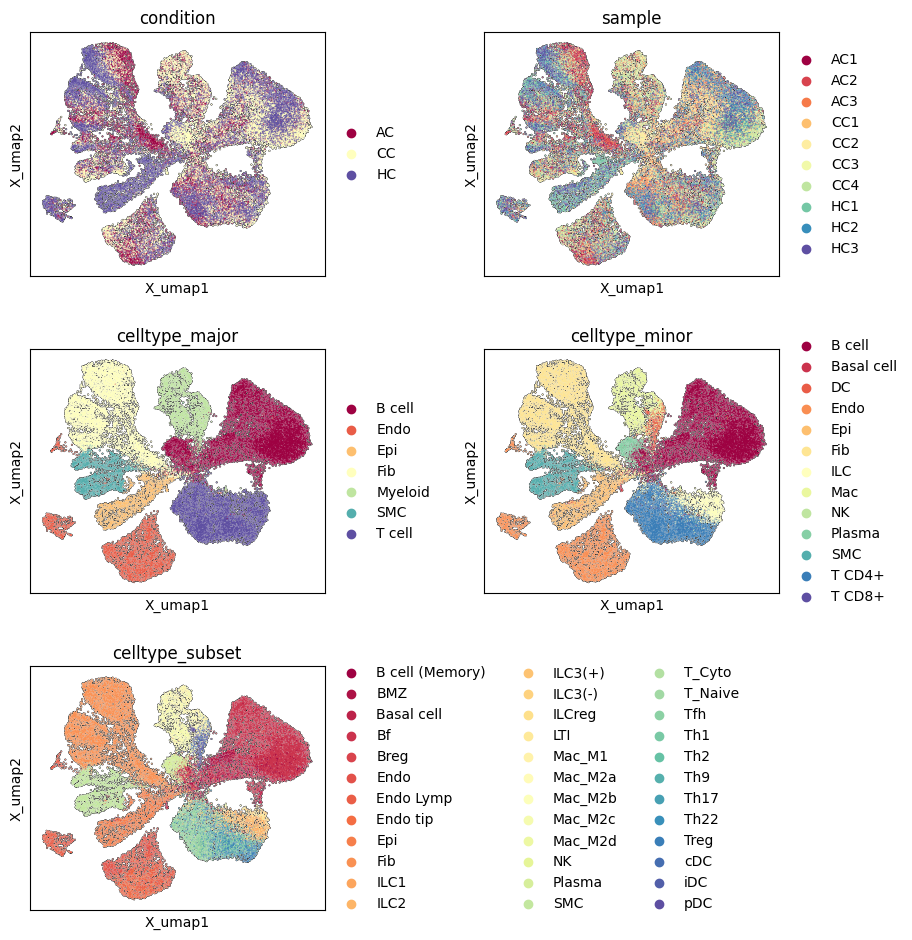

In [ ]:
items_to_plot = ['condition', 'sample',
                 'celltype_major', 'celltype_minor', 'celltype_subset']

## Abbreviate cell names
cols = ['celltype_major', 'celltype_minor', 'celltype_subset']
for col in cols:
    adata.obs[col] = adata.obs[col].astype(str)
    adata.obs[col].replace(rename_dict[col], inplace = True)

plt.rcParams['figure.figsize'] = (3.5, 3.5)
sc.pl.embedding( adata, basis = 'X_umap', neighbors_key = 'neighbors',
                 color=items_to_plot, wspace = 0.4, hspace = 0.3, legend_fontsize = 10,
                 ncols = 2, palette = 'Spectral', add_outline = True)

#### __A.3 Inspecting minor-type annotation result__

In [ ]:
adata.obs['celltype_minor'].value_counts()

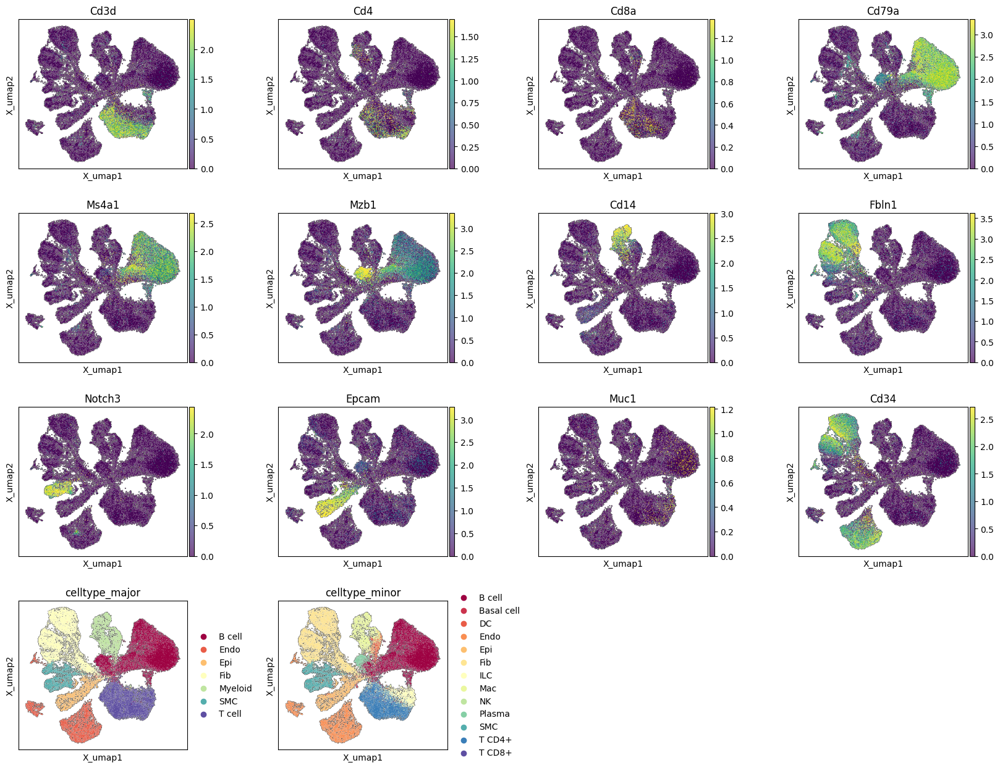

In [ ]:
items_to_plot = ['celltype_major', 'celltype_minor']

if adata_t.uns['usr_param']['species'] == 'human':
    genes = ['CD3D', 'CD4', 'CD8A', 'CD79A', 'MS4A1', 'MZB1',
             'CD14', 'LYZ', 'FBLN1', 'NOTCH3', 'EPCAM', 'MUC1',  'CD34']
else:
    genes = ['Cd3d', 'Cd4', 'Cd8a', 'Cd79a', 'Ms4a1', 'Mzb1',
             'Cd14', 'Lyz', 'Fbln1', 'Notch3', 'Epcam', 'Muc1',  'Cd34']

## 위 목록의 마커 유전자들 중 현재의 데이터에 있는 유전자들만 순서대로 선택
genes_all = list(adata.var.index.values)
items_to_plot = [g for g in genes if g in genes_all] + items_to_plot

plt.rcParams['figure.figsize'] = (3.5, 3.5)
sc.pl.embedding( adata, basis = 'X_umap', neighbors_key = 'neighbors',
                 color=items_to_plot, wspace = 0.4, hspace = 0.3,
                 legend_fontsize = 10,ncols = 4, palette = 'Spectral',
                 add_outline = True, vmax = 'p99', vmin = 0)

#### __A.4 Subset marker expression profile__
- Subset annotation은 UMAP으로 확인하기 어려우므로 dot plot을 사용하여 확인
- dot의 크기는 annotation 결과 기준으로 해당 유형의 세포 중 얼마나 많은 비율이 해당 유정의 마커 유전자를 발현하고 있는지 보여줌


Num markers selected: 154 -> 120


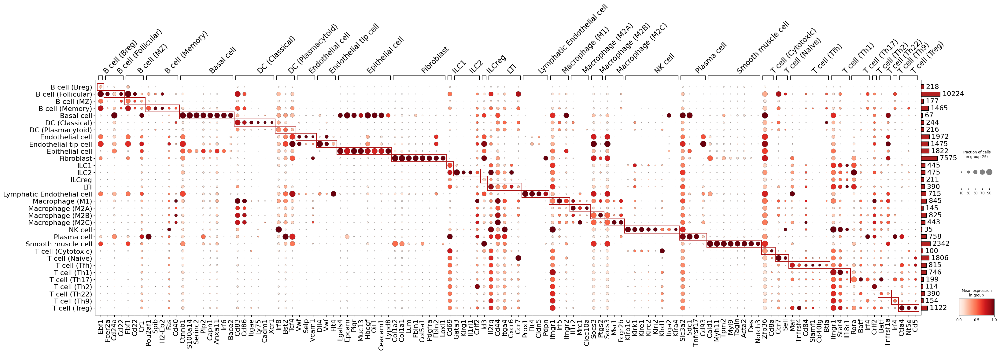

In [ ]:
plot_marker_exp(  adata_t, markers = None,
                  N_cells_per_group_min = 10, N_markers_per_group_max = 8, N_markers_total = 120,
                  title = None, title_y_pos = 1.1, title_fs = 30,
                  text_fs = 16, standard_scale = 'var',
                  var_group_rotation = 45, var_group_height = 1.2,
                  nz_frac_max = 0.9, nz_frac_cutoff = 0.05,
                  rem_mkrs_common_in_N_groups_or_more = 3,
                  figsize = None, swap_ax = False, legend = True,
                  cmap = 'Reds', linewidth = 1.5, linecolor = 'firebrick')

#### __Practice:__ Visualizing T-cell subsets

In [ ]:
b = adata_t.obs['celltype_major'] == 'Myeloid cell'
adata = adata_t[b,:].copy()

## UMAP 프로젝션을 얻기 위한 기본적 처리과정
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, n_top_genes = 1000)
try:
    sc.tl.pca(adata, n_comps = 15, mask_var="variable_genes")
except:
    sc.tl.pca(adata, n_comps = 15, use_highly_variable = True)
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=15, use_rep = 'X_pca')
sc.tl.umap(adata)

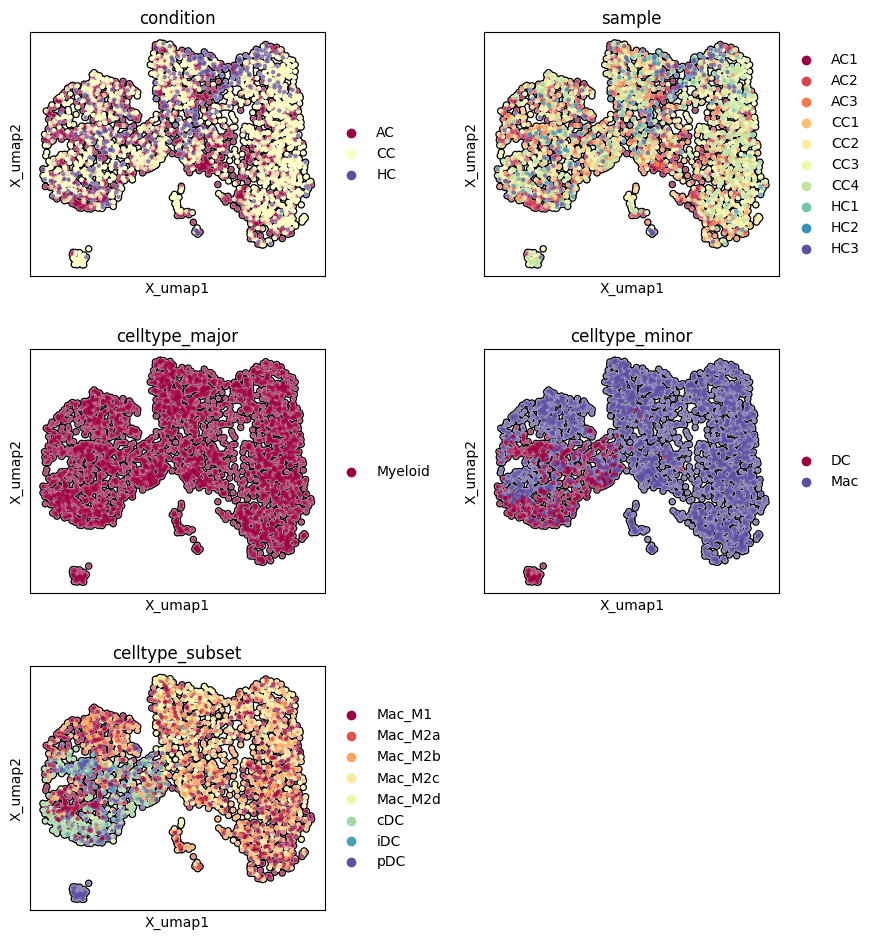

In [ ]:
items_to_plot = ['condition', 'sample',
                 'celltype_major', 'celltype_minor', 'celltype_subset']

cols = ['celltype_major', 'celltype_minor', 'celltype_subset']
for col in cols:
    adata.obs[col] = adata.obs[col].astype(str)
    adata.obs[col].replace(rename_dict[col], inplace = True)

plt.rcParams['figure.figsize'] = (3.5, 3.5)
sc.pl.embedding( adata, basis = 'X_umap', neighbors_key = 'neighbors',
                 color=items_to_plot, wspace = 0.4, hspace = 0.3, legend_fontsize = 10,
                 ncols = 2, palette = 'Spectral', add_outline = True)

#### __A.5 Inspecting celltype population__


,Group,B cell,Basal cell,Dendritic cell,Endothelial cell,Epithelial cell,Fibroblast,ILC,Macrophage,NK cell,Plasma cell,Smooth muscle cell,T cell CD4+,T cell CD8+
AC1,AC,10.5,0.0,1.6,18.3,0.7,40.1,5.1,5.6,0.0,0.2,9.1,8.4,0.3
AC2,AC,15.5,0.0,1.1,15.9,0.3,30.5,5.0,7.1,0.1,0.3,7.3,16.5,0.6
AC3,AC,33.1,0.0,2.4,9.1,0.8,9.6,5.1,7.4,0.2,0.9,4.2,26.6,0.6
CC1,CC,60.4,0.0,2.0,5.0,0.7,4.3,1.9,6.3,0.0,4.1,5.9,9.4,0.2
CC2,CC,61.0,0.9,1.1,5.1,1.0,3.3,1.1,4.8,0.0,5.7,5.9,9.9,0.1
CC3,CC,33.2,0.4,1.8,10.9,2.3,12.5,3.8,14.5,0.2,2.4,5.1,12.9,0.0
CC4,CC,23.8,0.2,2.1,14.6,1.5,20.5,4.8,10.7,0.3,1.6,7.6,12.2,0.1
HC1,HC,11.5,0.1,0.2,10.0,24.0,27.7,5.0,2.0,0.0,1.0,6.1,12.2,0.2
HC2,HC,45.9,0.1,0.6,5.9,4.1,15.6,4.1,2.1,0.0,1.6,3.4,16.5,0.2
HC3,HC,23.9,0.2,0.5,10.9,10.4,26.2,5.1,2.3,0.0,2.7,5.7,11.9,0.3


<Figure size 350x350 with 0 Axes>

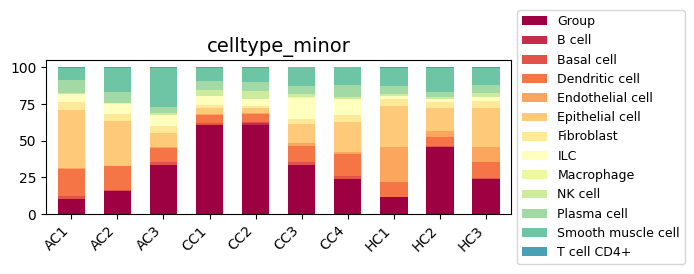

In [ ]:
## 샘플별 세포 개수 및  상대비율을 얻어서 데이터프레임에 저장
celltype_col = 'celltype_minor' ## 세포 유형의 기준
df_cnt, df_pct= get_population_per_sample( adata_t, celltype_col, sort_by = [] )

## 샘플별 세포 개수 확인
display(df_pct.round(1))

plot_population( df_pct, bar_width = 0.6,
                 title = celltype_col, title_fs = 14,
                 label_fs = 12, tick_fs = 10, xtick_rot = 45, xtick_ha = 'right',
                 legend_fs = 9, legend_loc = 'center left', bbox_to_anchor = (1,0.5),
                 legend_ncol = 1, cmap = None, figsize=(6, 2), dpi = 100)

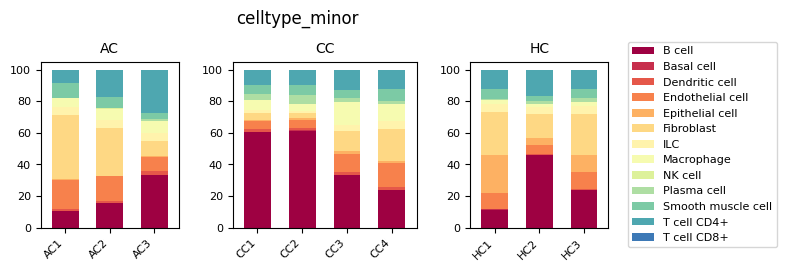

In [ ]:
## 샘플별 세포 개수 및  상대비율을 얻어서 데이터프레임에 저장
celltype_col = 'celltype_minor' ## 세포 유형의 기준
df_cnt, df_pct= get_population_per_sample( adata_t, celltype_col, sort_by = [], sample_col = 'sample' )

plot_population_grouped( df_pct, sort_by = [], bar_width = 0.6,
                         title = celltype_col, title_fs = 12, title_y_pos = 1.2,
                         label_fs = 10, tick_fs = 8, xtick_rot = 45, xtick_ha = 'right',
                         legend_fs = 8, legend_loc = 'center left', bbox_to_anchor = (1.1,0.5),
                         legend_ncol = 1, cmap = None, figsize=(7, 2), dpi = 100,
                         wspace = 0.35, hspace = 0.2 )

#### __A.6 Inspecting condition-specificity in celltype population__

In [ ]:
## 요부분은 sample 별 population을 얻어 조건별로 population이 유의하게
## 차이가 나는지 확인하는 부분입니다.
## 따라서, condition 당 sample이 최소 2개 이상 있는 경우 결과가 나오고
## sample이 많을 수록 통계적 유의성이 커짐 (p-value가 작아짐)

df_res = test_group_diff( df_pct, ref_group = None, pval_cutoff = 0.8 )
display(df_res)

,CC_vs_AC,HC_vs_AC,HC_vs_CC
Macrophage,0.355058,0.012532,0.049908
T cell CD8+,0.047697,0.083787,0.110198
Plasma cell,0.041801,0.100668,0.173140
Basal cell,0.147085,0.074224,0.249312
Epithelial cell,0.107844,0.172048,0.189586
ILC,0.082697,0.447987,0.112441
Fibroblast,0.196148,0.739884,0.066221
B cell,0.087581,0.581260,0.264463
NK cell,0.693346,0.132658,0.204918
T cell CD4+,0.367760,0.565312,0.240313


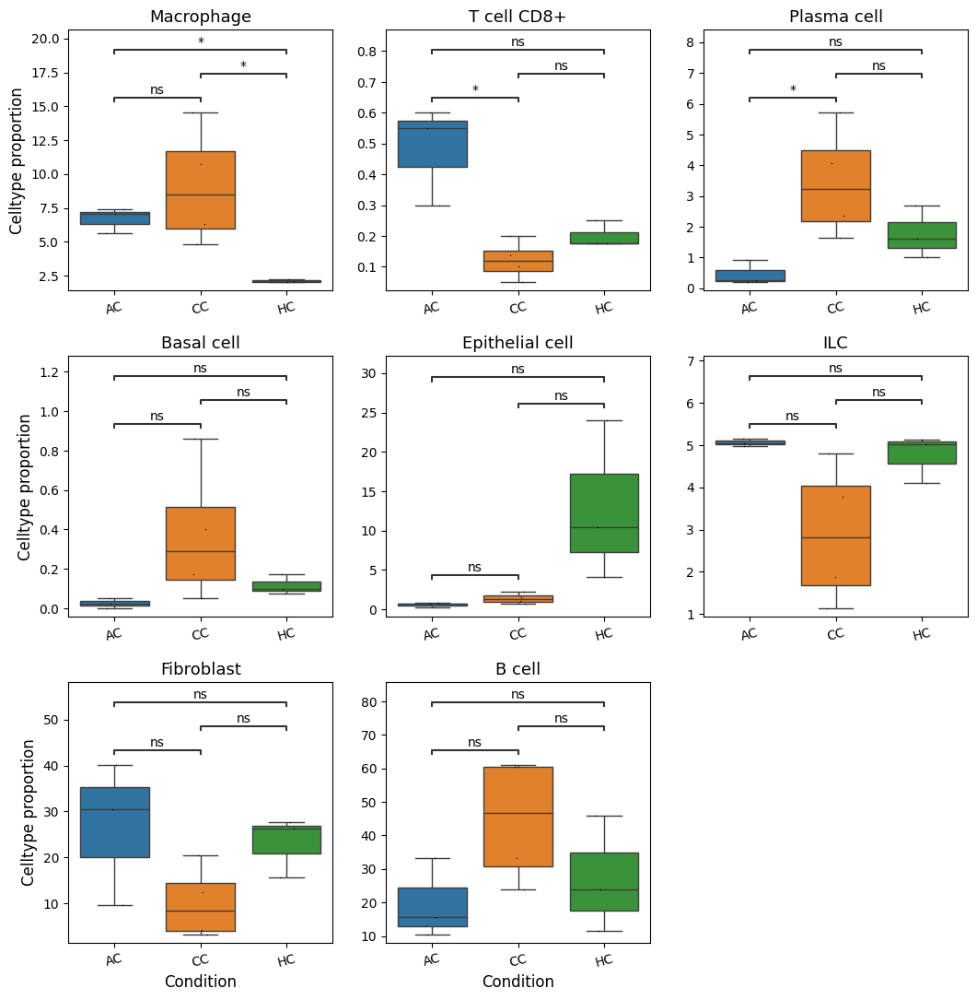

In [ ]:
## 표시할 결과 항목을 선택: 최대 8개만
max_n_items_to_plot = 8
idx_sel = df_res.index.values.tolist()[:min(max_n_items_to_plot, df_res.shape[0])]

if len(idx_sel) > 0:
    ## Show the first 5 CCIs
    plot_pct_box(df_pct[idx_sel], df_pct['Group'], ylabel = 'Celltype proportion',
                 ncols = 3, figsize = (3.5,3.5), dpi = 100,
                 group_order = None, # ['Normal', 'ER+', 'HER2+', 'TNBC'],
                 title = None, title_y_pos = 1.05, title_fs = 15,
                 label_fs = 12, tick_fs = 10, xtick_rot = 15,
                 annot_ref = None, annot_fmt = 'star', annot_fs = 10,
                 ws_hs = (0.2, 0.25), stripplot = True, cmap = 'tab10')

#### __Practice: Inspecting subset population__

,Group,Macrophage (M1),Macrophage (M2A),Macrophage (M2B),Macrophage (M2C),Macrophage (M2D)
AC1,AC,84,13,90,20,18
AC2,AC,96,12,110,44,20
AC3,AC,94,18,100,57,26
CC1,CC,94,9,80,47,23
CC2,CC,54,7,41,28,11
CC3,CC,226,33,179,105,38
CC4,CC,138,30,144,87,30
HC1,HC,17,3,33,18,10
HC2,HC,21,11,26,11,14
HC3,HC,21,9,22,26,12


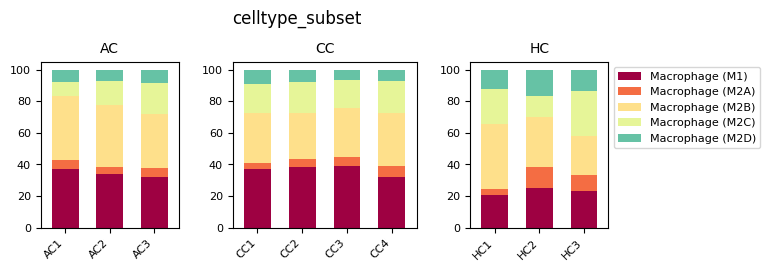

In [ ]:
## 특정 세포유형의 subset별 상대비율을 얻기 위해 특정 세포 유형만 선택
## 이 경우 Macrophage subset의 상대비율을 보기 위해 먼저 minor type이 macrophage인 cell들만 선택
b = adata_t.obs['celltype_minor'] == 'Macrophage'
adata_s = adata_t[b,:]

## 샘플별로 macrophage subset의 개수와 상대비율을 얻어서 데이터프레임에 저장
col = 'celltype_subset'
df_cnt, df_pct= get_population_per_sample( adata_s, col, sort_by = [] )
display(df_cnt)

plot_population_grouped( df_pct, sort_by = [],
                         title = col, title_fs = 12, title_y_pos = 1.2,
                         label_fs = 10, bar_width = 0.6,
                         tick_fs = 8, xtick_rot = 45, xtick_ha = 'right',
                         legend_fs = 8, legend_loc = 'upper left',
                         bbox_to_anchor = (1,1), legend_ncol = 1,
                         cmap = None, figsize=(7, 2), wspace = 0.35, dpi = 100)

In [ ]:
## 요부분은 sample 별 population을 얻어 조건별로 population이 유의하게
## 차이가 나는지 확인하는 부분입니다.
## 따라서, condition 당 sample이 최소 2개 이상 있는 경우 결과가 나오고
## sample이 많을 수록 통계적 유의성이 커짐 (p-value가 작아짐)

df_res = test_group_diff( df_pct, ref_group = None, pval_cutoff = 0.8 )
display(df_res)

,CC_vs_AC,HC_vs_AC,HC_vs_CC
Macrophage (M1),0.363900,0.006070,0.001048
Macrophage (M2D),0.649034,0.033522,0.027061
Macrophage (M2C),0.269760,0.286943,0.668414
Macrophage (M2B),0.057379,0.371449,0.867590
Macrophage (M2A),0.934072,0.326093,0.317669


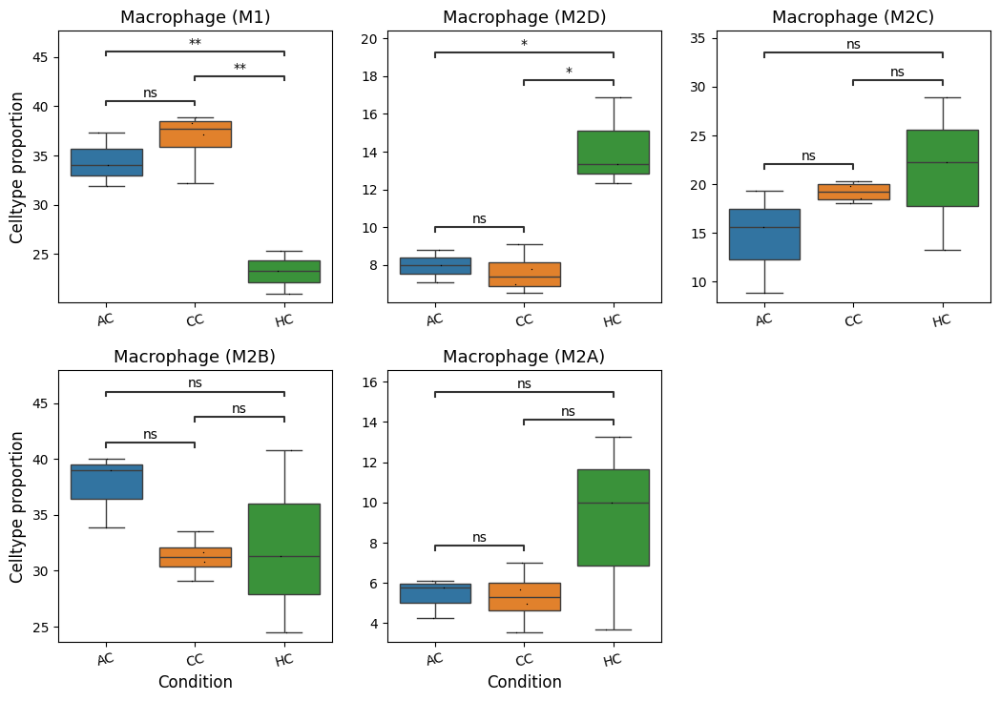

In [ ]:
## 표시할 결과 항목을 선택: 최대 8개만
max_n_items_to_plot = 8
idx_sel = df_res.index.values.tolist()[:min(max_n_items_to_plot, df_res.shape[0])]

if len(idx_sel) > 0:
    ## Show the first 5 CCIs
    plot_pct_box(df_pct[idx_sel], df_pct['Group'], ylabel = 'Celltype proportion',
                 ncols = 3, figsize = (3.5,3.5), dpi = 100,
                 group_order = None, # ['Normal', 'ER+', 'HER2+', 'TNBC'],
                 title = None, title_y_pos = 1.05, title_fs = 15,
                 label_fs = 12, tick_fs = 10, xtick_rot = 15,
                 annot_ref = None, annot_fmt = 'star', annot_fs = 10,
                 ws_hs = (0.2, 0.25), stripplot = True, cmap = 'tab10')

### __B. CNV & tumor cell identification 결과 (<font color=red>SKIP</font>)__
#### <font color=blue>(This works only if you checked "Tumor cell Identification" box when running SCODA)</font>

- __InferCNV:__ https://github.com/broadinstitute/infercnv
- __InferCNVpy:__ https://infercnvpy.readthedocs.io/en/latest/infercnv.html
- __InferPloidy:__ https://github.com/combio-dku/InferPloidy

#### __B.1 Inspecting CNV estimates using heatmap__
- We first group the cells into appropriate groups
- then compare the CNV patterns of the resulting cell groups using a heatmap.

In [ ]:
## adata_t의 사본을 만들어서 adata에 저장
## 이렇게하면 adata에 대해 처리한 내용이 원본에는 반영되지 않음
adata = adata_t[:,:].copy()

## cell들을 Grouping 하기 위해 obs 필드에 'cell_group' 열을 새로 정의
## 기본적으로 major type의 이름을 사용
adata.obs['cell_group'] = adata.obs['celltype_major'].astype(str).copy(deep = True)
adata.obs['cell_group'] = adata.obs['cell_group'].replace(rename_dict['celltype_major'])

## condition 열에 정의된 유방암 subtype에 따라 암세포로 식별된 세포들의
## 이름에 유방암 subtype을 추가하여 이름 변경
b = adata.obs['ploidy_dec'] == 'Aneuploid'
adata.obs.loc[b, 'cell_group'] = 'Aneuploid ' + adata.obs.loc[b, 'condition'].astype(str) \
                               + ' ' + adata.obs.loc[b, 'cell_group']

## 'cell_group'열 기준으로 Grouping하여 각 그룹별 CNV 패턴을 비교
axd = plot_cnv( adata, groupby = 'cell_group', N_cells_min = 200,
                title = 'log2(CNR)', title_fs = 12, title_y_pos = 1.1,
                label_fs = 12, tick_fs = 11,
                figsize = (15, 8), swap_axes = False,
                var_group_rotation = 90, cmap='RdBu_r', vmax = 1,
                cnv_obsm_key = 'X_cnv', cnv_uns_key = 'cnv', show_ticks = True,
                xlabel = 'Genomic spot', xtick_rot = 0, xtick_ha = 'center')

#### __B.2 Comparison of CNV patterns across samples using only cells identified as tumor cells__

In [ ]:
b = adata.obs['tumor_origin_ind']
adata_s = adata[b,:]

cell_grouping = 'sample_ext_for_deg'

## cell_grouping열 기준으로 Grouping하여 각 그룹별 CNV 패턴을 비교
axd, cna_res = plot_cnv( adata_s, groupby = cell_grouping, N_cells_min = 200,
                title = None, title_fs = 12, title_y_pos = 1.1,
                label_fs = 12, tick_fs = 10, Ns_min = 4, show_cna_spots = True,
                figsize = (15, 10), swap_axes = False,
                var_group_rotation = 90, cmap='bwr', vmax = 1,
                cnv_obsm_key = 'X_cnv', cnv_uns_key = 'cnv', show_ticks = True,
                xlabel = 'Genomic spot', xtick_rot = 0, xtick_ha = 'center')

In [ ]:
axes = plot_cnv_hit( cna_res['cnv_peaks_pos'], title = None, title_fs = 13,
                     label_fs = 12, tick_fs = 10, wspace = 0.1,
                     dpi = 150, ylabel = 'Genomic region',
                     bin_size = 0.22, cmap = 'Blues')

cna_res['genes']

#### __B.3 Finding genomic spots where CNV has a peak__

In [ ]:
## Select cells of interest
b = adata.obs['tumor_origin_ind']
adata_s = adata[b,:]

cnv_peaks = find_genomic_spots_of_cnv_peaks( adata_s, group_col = 'condition', width = 5, std_scale = 5, q = None )
cnv_peaks

#### __B.4 Visualizing CNV patterns using UMAP projection__

In [ ]:
# adata = adata_t[:,:]

sc.pp.neighbors(adata, n_neighbors=10, n_pcs=10, use_rep = 'X_cnv_pca', key_added = 'cnv_neighbors')
ad_tmp = sc.tl.umap(adata, neighbors_key = 'cnv_neighbors', copy = True)
adata.obsm['X_cnv_umap'] = ad_tmp.obsm['X_umap']

In [ ]:
items_to_plot = ['condition', 'celltype_major', 'cnv_ref_ind', 'ploidy_dec', 'sample']

adata.obs['cnv_ref_ind'] = adata.obs['cnv_ref_ind'].astype(str)
adata.obs['tumor_origin_ind'] = adata.obs['tumor_origin_ind'].astype(str)

plt.rcParams['figure.figsize'] = (3.5, 3.5)
fig = sc.pl.embedding( adata, basis = 'X_cnv_umap', neighbors_key = 'cnv_neighbors',
                       color=items_to_plot, wspace = 0.35, legend_fontsize = 10,
                       ncols = 2, palette = 'Spectral', return_fig = False,
                       add_outline = True)

#### __B.5  Inspecting aneuploid/diploid cell population__

In [ ]:
## 샘플별 세포 개수 및  상대비율을 얻어서 데이터프레임에 저장
b = adata_t.obs['tumor_origin_ind']
adata_s = adata_t[b,:]

col = 'ploidy_dec'
df_cnt, df_pct= get_population_per_sample( adata_s, col, sort_by = [] )

plot_population_grouped( df_pct, sort_by = ['Aneuploid'], bar_width = 0.6,
                 title = None, title_fs = 10, title_y_pos = 1.15, dpi = 120,
                 label_fs = 9, tick_fs = 8, xtick_rot = 90, xtick_ha = 'center',
                 legend_fs = 8, legend_loc = 'upper left', bbox_to_anchor = (1,1),
                 legend_ncol = 1, cmap = None, figsize=(6, 1), wspace = 0.35)

### __C. Cell-cell interaction analysis results__
- __CellPhoneDB:__ https://www.cellphonedb.org/

#### __C.1 Structure and format of the cell–cell interaction results__

<div>
<img src="https://drive.google.com/uc?export=view&id=1091cGa6DqKSybzWSd6YE7amC2HDqNIn6" align="center" width="320"/>
</div>

<div>
<img src=attachment:48abf5fd-8f00-4f14-9a91-bb5b872d7275.png width="320"/>   
</div>

- The CCI results are stored separately for each sample and each condition.
- The data format is consistent between the two result types.
- For condition-level CCI, only interactions that are commonly observed in a certain percentage of samples within the condition are retained.

In [ ]:
## 샘플 별 CCI 결과
cci_df_dct = adata_t.uns['CCI_sample']
sample_lst = list(cci_df_dct.keys())
sample_lst

In [ ]:
## CCI results in a data frame
cci_df_dct[sample_lst[-1]]

,gene_pair,cell_pair,gene_A,gene_B,cell_A,cell_B,pval,mean
PTPRC_CD22--B cell|B cell,PTPRC_CD22,B cell|B cell,PTPRC,CD22,B cell,B cell,0.0,1.159
SEMA4D_CD72--B cell|B cell,SEMA4D_CD72,B cell|B cell,SEMA4D,CD72,B cell,B cell,0.0,0.611
SEMA4D_PTPRC--B cell|B cell,SEMA4D_PTPRC,B cell|B cell,SEMA4D,PTPRC,B cell,B cell,0.0,1.002
NAMPT_NOX2_complex--B cell|B cell,NAMPT_NOX2_complex,B cell|B cell,NAMPT,NOX2_complex,B cell,B cell,0.0,0.537
PTPRC_MRC1--B cell|Endothelial cell,PTPRC_MRC1,B cell|Endothelial cell,PTPRC,MRC1,B cell,Endothelial cell,0.0,1.043
...,...,...,...,...,...,...,...,...
TGFB1_TGFBR3--T cell CD4+|Smooth muscle cell,TGFB1_TGFBR3,T cell CD4+|Smooth muscle cell,TGFB1,TGFBR3,T cell CD4+,Smooth muscle cell,0.0,1.308
LTB_LTBR--T cell CD4+|Smooth muscle cell,LTB_LTBR,T cell CD4+|Smooth muscle cell,LTB,LTBR,T cell CD4+,Smooth muscle cell,0.0,0.540
SELPLG_SELL--T cell CD4+|T cell CD4+,SELPLG_SELL,T cell CD4+|T cell CD4+,SELPLG,SELL,T cell CD4+,T cell CD4+,0.0,0.573
IFNG_Type_II_IFNR--T cell CD4+|T cell CD4+,IFNG_Type_II_IFNR,T cell CD4+|T cell CD4+,IFNG,Type_II_IFNR,T cell CD4+,T cell CD4+,0.0,0.401


In [ ]:
## Condition 별 CCI 결과
cci_df_dct_per_cond = adata_t.uns['CCI']
cond_lst = list(cci_df_dct_per_cond.keys())
cond_lst

['AC', 'CC', 'HC']

#### __C.2 Inspecting condition-specific CCIs__

In [ ]:
cci_df_dct_per_cond = adata_t.uns['CCI']

In [ ]:
adata_t.obs['celltype_for_cci'].value_counts()

4 cell_pairs, 101 gene_pairs found


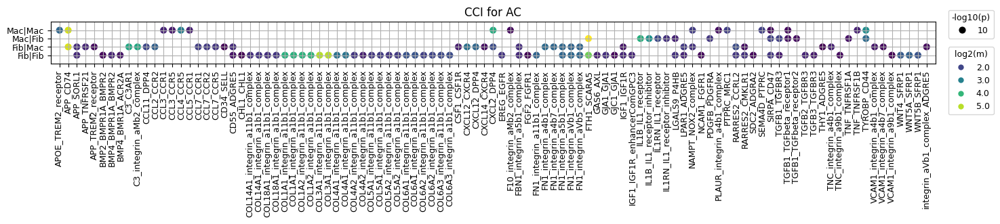

9 cell_pairs, 101 gene_pairs found


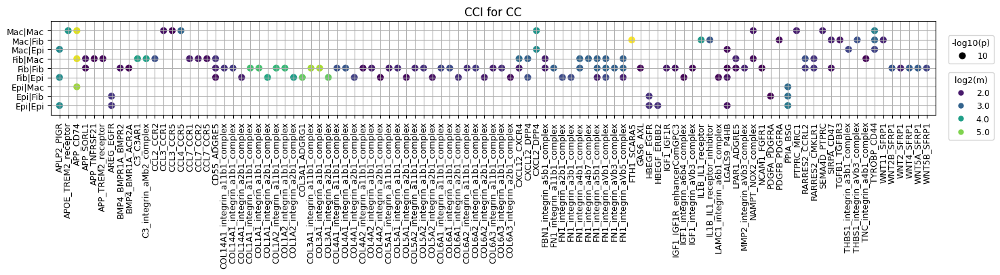

9 cell_pairs, 101 gene_pairs found


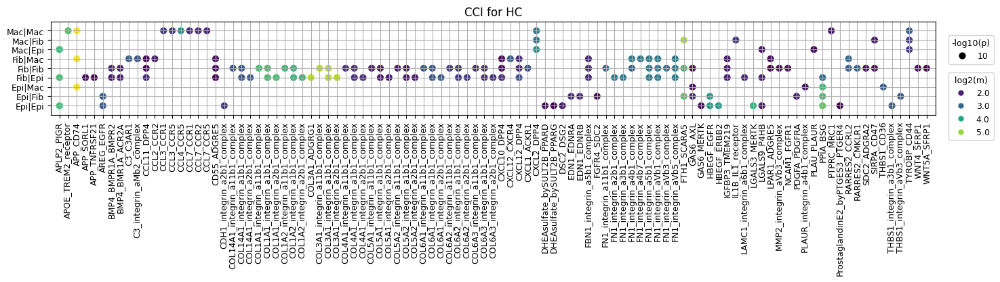

In [ ]:
## 특정 target cell이 포함된 interaction들만 확인함. (모든 CCI를 다 보려면 target_cells을 []로 설정)
target_cells = ['Epithelial cell', 'Macrophage', 'Fibroblast']
target_genes = []

ax = plot_cci_dot( cci_df_dct_per_cond, n_gene_pairs = 100,
                   target_cells = target_cells, target_genes = target_genes,
                   pval_cutoff = 0.1, mean_cutoff = 0.1,
                   rename_cells = rename_dict['celltype_minor'],
                   title = None, title_fs = 12,
                   legend_fs = 9, legend_mkr_sz = 9,
                   tick_fs = 9, xtick_rot = 90, xtick_ha = 'center',
                   dpi = 100, swap_ax = True, cmap = None )

#### __C.3 Exploring CCis associated with a specific gene set__  

In [ ]:
b1 = adata_t.var_names.str.startswith('Ccl')
b2 = adata_t.var_names.str.startswith('Cxcl')
b3 = adata_t.var_names.str.startswith('Il')

genes_sel = list(adata_t.var.index.values[b1 | b2 | b3])
np.array(genes_sel)

array(['Il17a', 'Il17f', 'Il1r2', 'Il1r1', 'Il1rl2', 'Il1rl1', 'Il18r1',
       'Il18rap', 'Ccl20', 'Ilkap', 'Il24', 'Il19', 'Il10', 'Ildr2',
       'Il2ra', 'Il15ra', 'Il1f9', 'Il1f6', 'Il1rn', 'Il1a', 'Il1b',
       'Il1bos', 'Il7', 'Il2', 'Il21', 'Il12a', 'Il6ra', 'Ilf2',
       'Il11ra1', 'Ccl27a', 'Ccl19', 'Ccl21a', 'Il22ra1', 'Il6', 'Cxcl5',
       'Cxcl3', 'Cxcl1', 'Cxcl2', 'Cxcl9', 'Cxcl10', 'Cxcl13', 'Il31',
       'Ccl24', 'Il12rb2', 'Il23r', 'Il5ra', 'Il17re', 'Il17rc', 'Cxcl12',
       'Il17ra', 'Il11', 'Cxcl17', 'Il4i1', 'Il16', 'Il18bp', 'Ilk',
       'Il4ra', 'Il21r', 'Il27', 'Ccl25', 'Il12rb1', 'Il15', 'Il27ra',
       'Ccl22', 'Ccl17', 'Il34', 'Il17c', 'Ilf3', 'Il10ra', 'Il18',
       'Il20rb', 'Il22ra2', 'Il20ra', 'Ilvbl', 'Il22', 'Iltifb', 'Il23a',
       'Il9r', 'Il12b', 'Il4', 'Il13', 'Il5', 'Cxcl16', 'Ccl2', 'Ccl7',
       'Ccl11', 'Ccl12', 'Ccl8', 'Ccl1', 'Ccl5', 'Ccl9', 'Ccl6', 'Ccl3',
       'Ccl4', 'Cxcl14', 'Il6st', 'Il31ra', 'Ccl28', 'Il3ra', 'Il17rd',
     

4 cell_pairs, 29 gene_pairs found


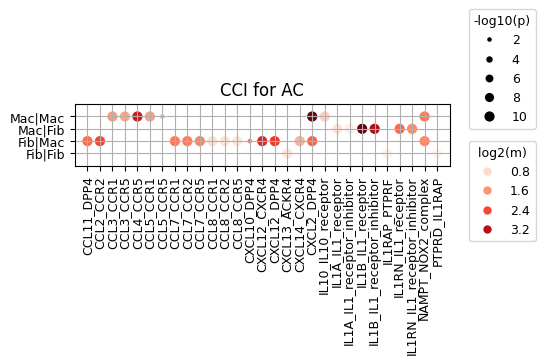

8 cell_pairs, 30 gene_pairs found


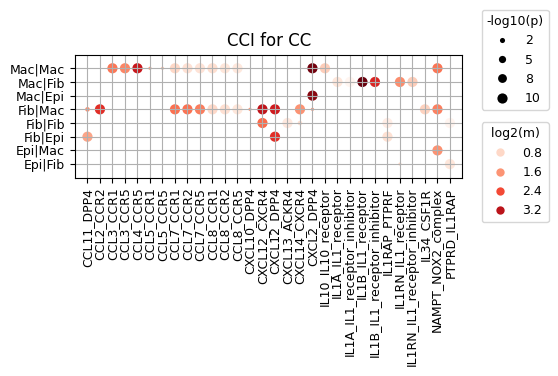

9 cell_pairs, 23 gene_pairs found


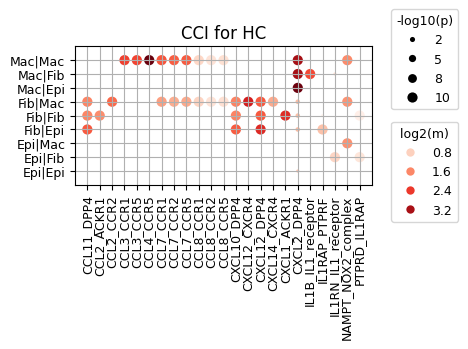

In [ ]:
## 특정 target cell이 포함된 interaction들만 확인함. (모든 CCI를 다 보려면 target_cells을 []로 설정)
target_cells = ['Epithelial cell', 'Macrophage', 'Fibroblast']

## CellPhoneDB는 인간 유전자 이름만 사용하므로 마우스의 경우 유전자 이름을 대문자로 변경 필요.
target_genes = [g.upper() for g in genes_sel] + ['NAMPT']

ax = plot_cci_dot( cci_df_dct_per_cond, n_gene_pairs = 60,
                   target_cells = target_cells, target_genes = target_genes,
                   pval_cutoff = 0.1, mean_cutoff = 0.1,
                   rename_cells = rename_dict['celltype_minor'],
                   title = None, title_fs = 12,
                   legend_fs = 9, legend_mkr_sz = 9,
                   tick_fs = 9, xtick_rot = 90, xtick_ha = 'center',
                   dpi = 100, swap_ax = True, cmap = 'Reds')

#### __C.4 Inspecting per-sample CCIs__

In [ ]:
cci_df_dct = adata_t.uns['CCI_sample']

## 특정 target cell이 포함된 interaction들만 확인함. (모든 CCI를 다 보려면 target_cells을 []로 설정)
target_cells = ['Epithelial cell', 'Macrophage', 'Fibroblast']
target_genes = []

ax = plot_cci_dot( cci_df_dct, n_gene_pairs = 100,
                   target_cells = target_cells, target_genes = target_genes,
                   pval_cutoff = 0.1, mean_cutoff = 0.1,
                   rename_cells = rename_dict['celltype_minor'],
                   title = None, title_fs = 12,
                   legend_fs = 9, legend_mkr_sz = 9,
                   tick_fs = 9, xtick_rot = 90, xtick_ha = 'center',
                   dpi = 100, swap_ax = True, cmap = None )

#### __C.5 Statistical test for condition-specific differences in CCI strength__
샘플별 CCI 결과에서 모든 샘플에서 공통적으로 확인된 CCI를 골라서 \
각 조건별로 상호작용의 강도간 유의한 차이가 있는지 확인할 수 있음

In [ ]:
target_cells = ['Epithelial cell', 'Macrophage', 'Fibroblast']
target_genes = []

## mean 값을 가져오된 pval가 cutoff 보다 작은 것들만 가져옴
df = get_cci_means( adata_t, cci_idx_lst = None,
                    cells = target_cells, genes = target_genes, pval_cutoff = 0.1 )
## cci_idx_lst를 None으로 설정하면 cci_df_dct에 있는 모든 CCI들의 union에 대한 결과를 리턴함 (pval_cutoff은 적용됨)
## 리턴 결과가 0인 것은 해당 샘플에서 해당 CCI가 검출되지 않은 것임.

df_res = test_group_diff( df, ref_group = None, pval_cutoff = 0.05 )
df_res

,CC_vs_AC,HC_vs_AC,HC_vs_CC
SELPLG_SELP--Macrophage|Endothelial cell,0.003672,0.002276,0.001450
THY1_ADGRE5--T cell CD4+|Macrophage,0.010657,0.008975,0.000315
integrin_aVb1_complex_ADGRE5--Fibroblast|Macrophage,0.004311,0.030188,0.000616
THY1_ADGRE5--Fibroblast|Macrophage,0.007508,0.031405,0.000466
VCAM1_integrin_a9b1_complex--Endothelial cell|Fibroblast,0.018365,0.014649,0.001329
...,...,...,...
TGM2_ADGRG1--Endothelial cell|Epithelial cell,1.000000,1.000000,0.047549
TNFSF13B_TNFRSF13C--Fibroblast|Plasma cell,1.000000,1.000000,0.047963
TGFB2_TGFbeta_receptor1--Endothelial cell|Macrophage,1.000000,1.000000,0.048134
SEMA4G_PLXNB2--Epithelial cell|Smooth muscle cell,1.000000,1.000000,0.048911


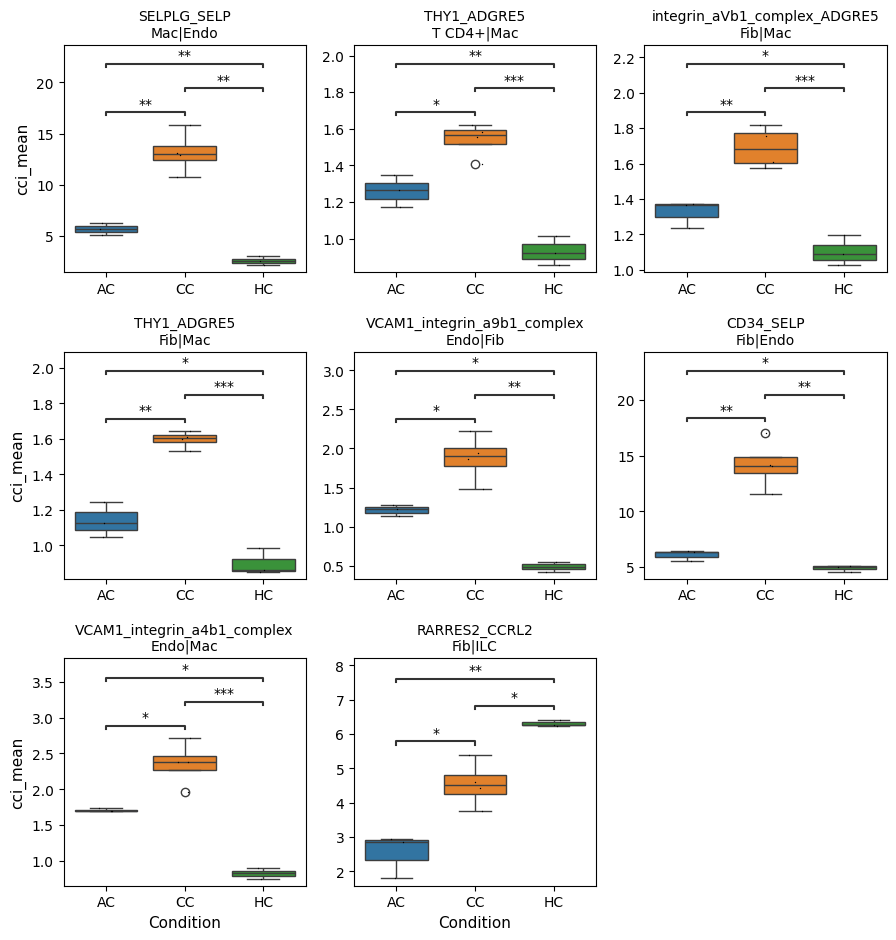

In [ ]:
## 요부분은 sample 별 CCI의 mean이(CCI의 강도가) 조건별로 유의하게
## 차이가 나는지 확인하는 부분입니다.
## 따라서, condition 당 sample이 최소 2개 이상 있는 경우 결과가 나오고
## sample이 많을 수록 통계적 유의성이 커지고요. (p-value가 작아지고요)

## 표시할 결과 항목을 선택: 앞에서 8개만
max_n_items_to_plot = 8
idx_sel = df_res.index.values.tolist()[:min(max_n_items_to_plot, df_res.shape[0])]

if len(idx_sel) > 0:
    plot_pct_box(df[idx_sel], df['Group'], ylabel = 'cci_mean',
              ncols = 3, figsize = (3,3), dpi = 100, rename_cells = rename_dict['celltype_minor'],
              title = None, title_y_pos = 1.05, title_fs = 12,
              label_fs = 11, tick_fs = 10, xtick_rot = 0, xtick_ha = 'center',
              annot_ref = None, annot_fmt = 'star', annot_fs = 10,
              ws_hs = (0.2, 0.35), stripplot = True)

#### __C.6 Statistical test for condition-specific differences in CCI strength (specifying genes to consider)__
샘플별 CCI 결과에서 여러 샘플에서 공통적으로 확인된 CCI를 골라서 \
각 조건별로 상호작용의 강도간 유의한 차이가 있는지 확인할 수 있음

In [ ]:
target_cells = ['Epithelial cell', 'Macrophage', 'Fibroblast']
target_genes = ['IL1B', 'NAMPT']

## mean 값을 가져오된 pval가 cutoff 보다 작은 것들만 가져옴
df = get_cci_means( adata_t, cci_idx_lst = None,
                    cells = target_cells, genes = target_genes, pval_cutoff = 0.2 )
## cci_idx_lst를 None으로 설정하면 cci_df_dct에 있는 모든 CCI들의 union에 대한 결과를 리턴함 (pval_cutoff은 적용됨)
## 리턴 결과가 0인 것은 해당 샘플에서 해당 CCI가 검출되지 않은 것임.

df_res = test_group_diff( df, ref_group = None, pval_cutoff = 0.5 )
df_res

,CC_vs_AC,HC_vs_AC,HC_vs_CC
NAMPT_NOX2_complex--Endothelial cell|Macrophage,0.466088,0.032124,0.019277
NAMPT_NOX2_complex--Macrophage|B cell,0.164421,0.061950,0.159989
IL1B_IL1_receptor--Macrophage|Fibroblast,0.847721,0.008869,0.041462
NAMPT_NOX2_complex--Macrophage|Macrophage,0.540377,0.108799,0.029954
NAMPT_NOX2_complex--B cell|Macrophage,0.591366,0.085859,0.045431
NAMPT_NOX2_complex--Smooth muscle cell|Macrophage,0.509970,0.098347,0.049636
NAMPT_NOX2_complex--Fibroblast|Macrophage,0.511918,0.119960,0.057313
NAMPT_NOX2_complex--T cell CD4+|Macrophage,0.624058,0.414807,0.055646
NAMPT_NOX2_complex--ILC|Macrophage,0.888455,0.394724,0.050030
NAMPT_NOX2_complex--Plasma cell|Macrophage,1.000000,1.000000,0.068146


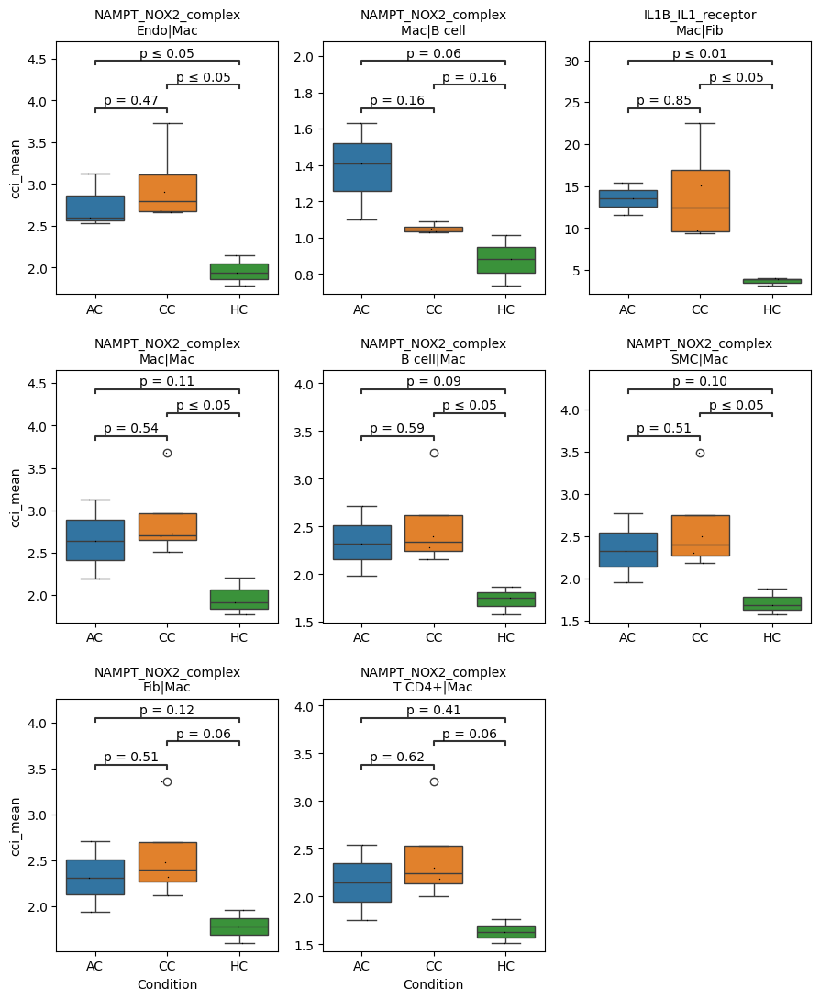

In [ ]:
## 요부분은 sample 별 CCI의 mean이(CCI의 강도가) 조건별로 유의하게
## 차이가 나는지 확인하는 부분입니다.
## 따라서, condition 당 sample이 최소 2개 이상 있는 경우 결과가 나오고
## sample이 많을 수록 통계적 유의성이 커지고요. (p-value가 작아지고요)

## 표시할 결과 항목을 선택: 앞에서 8개만
max_n_items_to_plot = 8
idx_sel = df_res.index.values.tolist()[:min(max_n_items_to_plot, df_res.shape[0])]

if len(idx_sel) > 0:
    ## Show the selected CCIs
    plot_pct_box(df[idx_sel], df['Group'], ylabel = 'cci_mean',
              ncols = 3, figsize = (3,3.5), dpi = 100, rename_cells = rename_dict['celltype_minor'],
              title = None, title_y_pos = 1.05, title_fs = 12,
              label_fs = 10, tick_fs = 10, xtick_rot = 0, xtick_ha = 'center',
              annot_ref = None, annot_fmt = 'simple', annot_fs = 10,
              ws_hs = (0.2, 0.3), stripplot = True)

#### __C.7 Circle plots for an overview of cell-cell interactions__

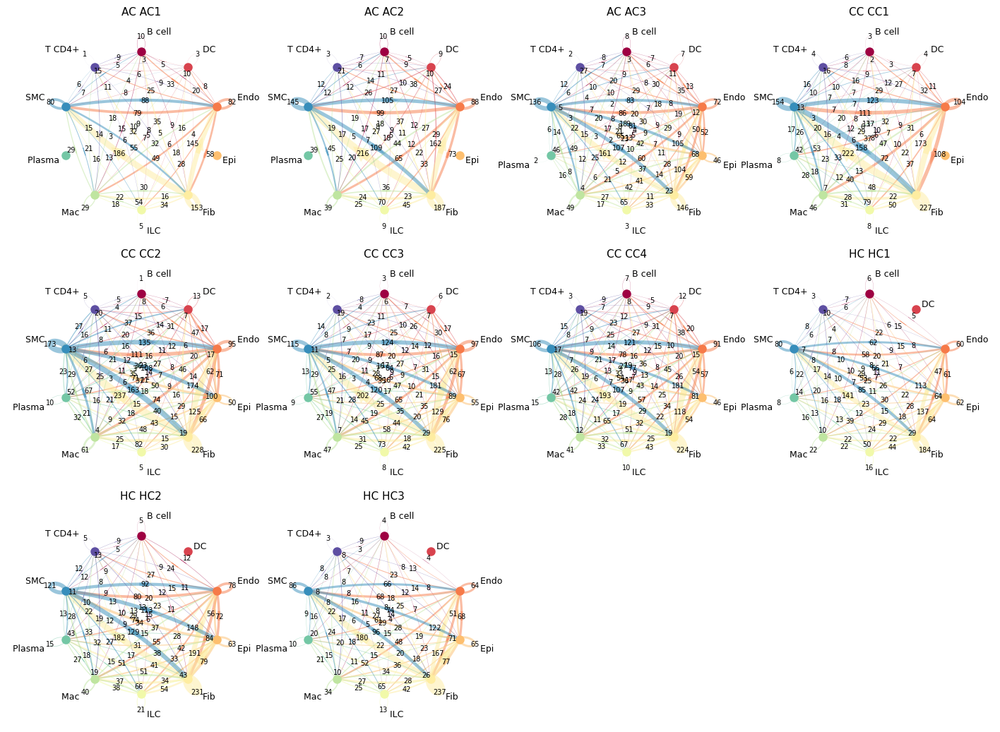

In [ ]:
## DataFrame들의 dictionalry로 되어 있는 CCI 결과를 가져옴
cci_df_dct = adata_t.uns['CCI_sample']

plot_cci_circ_group( cci_df_dct, target = None,
                     rename_cells = rename_dict['celltype_minor'],
                     remove_common = False, ncol = 4, figsize = (3.5,3.5),
                     title = None, title_y_pos = 1.1, title_fs = 24,
                     text_fs = 9, num_fs = 7, margin = 0.08,
                     dpi = 100, alpha = 0.5, R_curvature = 3,
                     linewidth_max = 8, linewidth_log = False,
                     node_size = 8, rot = False, cmap = 'Spectral',
                     wspace = 0.15, hspace = 0.1 )

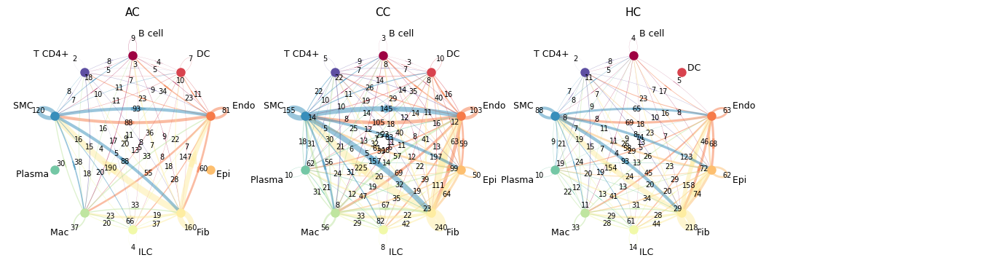

In [ ]:
## DataFrame들의 dictionalry로 되어 있는 CCI 결과를 가져옴
cci_df_dct_per_cond = adata_t.uns['CCI']

plot_cci_circ_group( cci_df_dct_per_cond, target = None,
                     rename_cells = rename_dict['celltype_minor'],
                     remove_common = False, ncol = 4, figsize = (3.5,3.5),
                     title = None, title_y_pos = 1.1, title_fs = 24,
                     text_fs = 9, num_fs = 7, margin = 0.08,
                     dpi = 100, alpha = 0.5, R_curvature = 3,
                     linewidth_max = 8, linewidth_log = False,
                     node_size = 8, rot = False, cmap = 'Spectral',
                     wspace = 0.15, hspace = 0.1 )

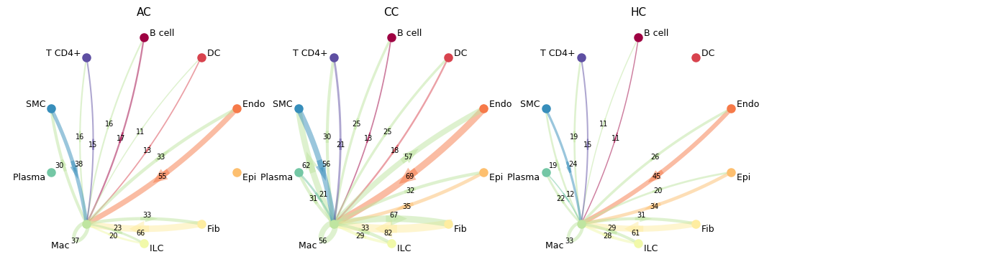

In [ ]:
## DataFrame들의 dictionalry로 되어 있는 CCI 결과를 가져옴
cci_df_dct_per_cond = adata_t.uns['CCI']

## 특정 세포유형을 중심으로 CCI 개수 확인 (이 경우 Epithelial cell을 중심으로 봄)
target = ['Mac']

plot_cci_circ_group( cci_df_dct_per_cond, target = target,
                     rename_cells = rename_dict['celltype_minor'],
                     remove_common = False, ncol = 4, figsize = (3.5,3.5),
                     title = None, title_y_pos = 1.1, title_fs = 24,
                     text_fs = 9, num_fs = 7, margin = 0.08,
                     dpi = 100, alpha = 0.5, R_curvature = 3,
                     linewidth_max = 8, linewidth_log = False,
                     node_size = 8, rot = False, cmap = 'Spectral',
                     wspace = 0.15, hspace = 0.1 )

### __D. DEG analysis results and marker/target discovery__

In [ ]:
adata_t

In [ ]:
nc_deg_dct_of_dct = adata_t.uns['DEG_stat'] ## DEG 분석에 사용된 셀수 정보
df_deg_dct_of_dct = adata_t.uns['DEG'] ## DEG 분석 결과

## 어떤 세포 유형들에 대한 DEG 결과가 있는지 확인
list(df_deg_dct_of_dct.keys())

## analysis_parameters에 정의한 DEG분석을 위한 최소 셀수(MIN_NUM_CELLS_FOR_DEG)보다
## 적은 셀수를 갖는 세포 유형에 대해서는 DEG 분석이 수행 되지 않음.
## (각 조건 별로 해당 유형의 셀수가 최소한 MIN_NUM_CELLS_FOR_DEG 정도되어야 DEG 분석이 수행됨)

['B cell',
 'Dendritic cell',
 'Endothelial cell',
 'Epithelial cell',
 'Fibroblast',
 'ILC',
 'Macrophage',
 'Plasma cell',
 'Smooth muscle cell',
 'T cell CD4+']

#### __D.1 Structure and format of the DEG results__

<div>
<img src="https://drive.google.com/uc?export=view&id=1N-XeRpAvUAlnuryLpll7sYyzGbKGK5eG" align="center" width="500"/>
</div>

<div>
<img src=attachment:f57fafbd-8253-4210-88ed-9acbc3224d08.png width="500"/>   
</div>

- The DEG results are processed and stored separately for each cell type.
- The cell type level to be used—major, minor, or subset—can be specified in the analysis_parameters when running SCODA.
- The current results are based on the celltype_minor level and reflect condition-specific DEGs identified for each cell type.

In [ ]:
## 특정 세포 유형에 대한 DEG 분석 결과를 가져옴 (이경우 Epithelial cell)
target_cell = 'Macrophage'

df_deg_dct = df_deg_dct_of_dct[target_cell]
nc_deg_dct = nc_deg_dct_of_dct[target_cell]

## 해당 세포 유형에 사용된 조건 별 셀수 확인
nc_deg_dct

{'AC_vs_others': {'AC': 540, 'others': 935},
 'CC_vs_others': {'CC': 681, 'others': 794},
 'HC_vs_others': {'HC': 254, 'others': 1221}}

In [ ]:
df_deg_dct['CC_vs_others'].head()

,log2_FC,pval,pval_adj,mean_test,mean_ref,nz_pct_test,nz_pct_ref,nz_pct_score,nz_pct_pval,gene,Rp
Ighg2b,4.971,2.207079e-46,1.720638e-42,1.051910,0.057704,0.455213,0.068519,0.394969,1.056801e-34,Ighg2b,1.0
Iglc2,1.463,2.865546e-06,2.233979e-02,0.527320,0.224585,0.289280,0.102362,0.233089,2.437080e-09,Iglc2,1.0
1810058I24Rik,0.680,1.311288e-03,1.000000e+00,0.687963,0.481120,0.440529,0.301852,0.214718,1.273383e-05,1810058I24Rik,1.0
Ighm,1.385,7.452680e-10,5.810109e-06,1.195963,0.632877,0.496329,0.342520,0.214553,2.652119e-05,Ighm,1.0
Retreg1,0.668,6.063631e-03,1.000000e+00,0.517037,0.355060,0.353891,0.229630,0.210024,2.509738e-04,Retreg1,1.0


- nz_pct_score = nz_pct_test*(1-nz_pct_ref)
- nz_pct_test: percentage of cells with the gene expressed in test group
- nz_pct_ref: percentage of cells with the gene expressed in reference group

#### __D.2 Gene ranking per celltype__

Macrophage


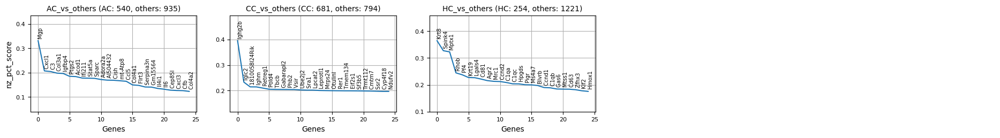

In [ ]:
key = 'Macrophage'
df_deg_dct = df_deg_dct_of_dct[key]
nc_deg_dct = nc_deg_dct_of_dct[key]

n_genes_to_show = 25

print(key)
plot_deg( df_deg_dct, reference = 'nz_pct_score',
          n_genes_to_show = n_genes_to_show, pval_cutoff = 0.01,
          figsize = (4,2), dpi = 100, text_fs = 7, title_fs = 10, label_fs = 10,
          tick_fs = 8, ncols = 5, wspace = 0.2, hspace = 0.5,
          deg_stat_dct = nc_deg_dct, show_log_pv = False )


In [ ]:
n_genes_to_show = 25

for key in df_deg_dct_of_dct.keys():
    df_deg_dct = df_deg_dct_of_dct[key]
    nc_deg_dct = nc_deg_dct_of_dct[key]

    print(key)
    plot_deg( df_deg_dct, reference = 'nz_pct_score',
              n_genes_to_show = n_genes_to_show, pval_cutoff = 0.01,
              figsize = (4,2), dpi = 100, text_fs = 7, title_fs = 10, label_fs = 10,
              tick_fs = 8, ncols = 5, wspace = 0.2, hspace = 0.5,
              deg_stat_dct = nc_deg_dct, show_log_pv = False )


#### __D.3 Discovery of condition-specific markers (per-celltype)__

In [ ]:
adata_t

AnnData object with n_obs × n_vars = 38900 × 20582
    obs: 'sample', 'condition', 'celltype_major', 'celltype_minor', 'celltype_subset', 'sample_ext', 'celltype_for_cci'
    var: 'gene_ids', 'feature_types', 'variable_genes'
    uns: 'CCI', 'CCI_sample', 'Celltype_marker_DB', 'DEG', 'DEG_grouping_vars', 'DEG_stat', 'DEG_vs_ref', 'DEG_vs_ref_stat', 'GSA_down', 'GSA_up', 'GSA_vs_ref_down', 'GSA_vs_ref_up', 'GSEA', 'GSEA_vs_ref', 'HiCAT_summary', 'Pathways_DB', 'analysis_parameters', 'log', 'lut_sample_to_cond', 'usr_param'
    obsm: 'HiCAT_result', 'X_pca'

In [ ]:
nc_deg_dct_of_dct = adata_t.uns['DEG_stat']
df_deg_dct_of_dct = adata_t.uns['DEG']
df_deg_dct_of_dct.keys()

dict_keys(['B cell', 'Dendritic cell', 'Endothelial cell', 'Epithelial cell', 'Fibroblast', 'ILC', 'Macrophage', 'Plasma cell', 'Smooth muscle cell', 'T cell CD4+'])

In [ ]:
# target_cell = 'Fibroblast'
# target_cell = 'Macrophage'
# target_cell = 'Ductal cell'
target_cell = 'Macrophage'

df_deg_lst = df_deg_dct_of_dct[target_cell]

mkr_dict, df_deg_dct_updated = find_condition_specific_markers( df_deg_lst,
                                            score_col = 'nz_pct_score',
                                            n_markers_max = 60,
                                            score_cutoff = 0.15,
                                            pval_cutoff = 0.05,
                                            nz_pct_fc_cutoff = 1.25,
                                            surfaceome_only = True,
                                            verbose = True )

## Print results
for key in mkr_dict.keys():
    mkr_dict[key].sort()
    print('%s (%i): ' % (key, len(mkr_dict[key])), mkr_dict[key])


N_markers: 
   AC_vs_others (7442 -> 1) 
   CC_vs_others (7513 -> 19) 
   HC_vs_others (7541 -> 8)
N_markers_selected: AC (1), CC (19), HC (8)
AC (1):  ['Adora2a']
CC (19):  ['Abca1', 'Adam10', 'Bsg', 'C5ar1', 'Ccr1', 'Cd38', 'Cd82', 'Cd93', 'Crlf2', 'Ebp', 'F11r', 'Fam174a', 'Gpr141', 'Ifngr1', 'Nfam1', 'Pilra', 'Rnf13', 'Slc49a4', 'Vsir']
HC (8):  ['Axl', 'Cd36', 'Cd63', 'Epcam', 'Mrc1', 'Nrp1', 'Pigr', 'Stab1']


Num markers selected: 28 -> 28


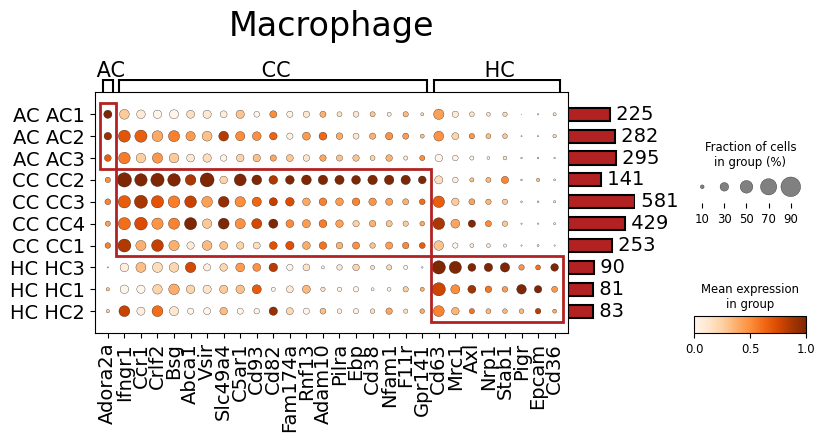

In [ ]:
target_cell = 'Macrophage'
title = target_cell

plot_marker_exp(adata_t, markers = mkr_dict, celltype_selection = target_cell,
                N_cells_per_group_min = 40, N_markers_per_group_max = 30, N_markers_total = 140,
                title = title, title_y_pos = 2, title_fs = 24, text_fs = 14,
                var_group_height = 1.2, var_group_rotation = 0,
                standard_scale = 'var', nz_frac_max = 0.9, nz_frac_cutoff = 0.05,
                rem_mkrs_common_in_N_groups_or_more = 3, legend = True,
                figsize = None, swap_ax = False, add_rect = True,
                cmap = 'Oranges', linewidth = 2, linecolor = 'firebrick' )

#### __D.4 Examining expression patterns of selected markers using violin plots__

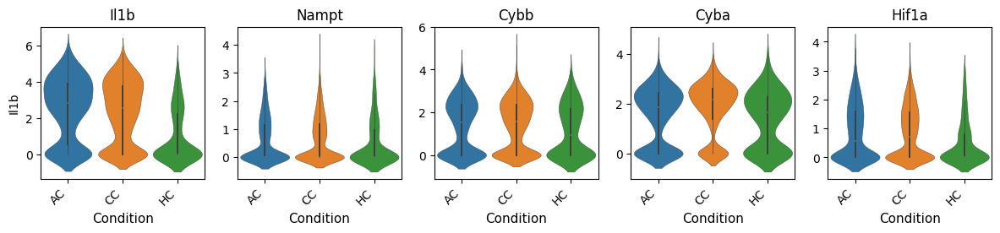

In [ ]:
items_to_plot = ['Il1b', 'Nampt', 'Cybb', 'Cyba', 'Hif1a']

b = adata_t.obs['celltype_minor'] == 'Macrophage'
adata_s = adata_t[b,:]

## RNA Expression의 log변환 값을 기준으로 violin plot을 확인
sc.pp.normalize_total(adata_s, target_sum=1e4)
sc.pp.log1p(adata_s)

df = adata_s[:, items_to_plot].to_df()
df['group'] = adata_s.obs['condition']

plot_violin( df, genes_lst = items_to_plot, group_col = 'group', scale = 'width',
             group_order = None, inner = 'box', width = 0.9, linewidth = 0.3, bw = 'scott',
             figsize = (2.5,2), dpi = 100,
             text_fs = 10, title = None, title_fs = 14, title_y_pos = 1,
             label_fs = 11, tick_fs = 10, xtick_rot = 45, xtick_ha = 'right',
             ncols = 5, wspace = 0.2, hspace = 0.3, cmap = 'tab10' )

#### __D.5 Statistical test for mean-expression of condition-specific markers__
- 요부분은 sample 별 Gene expression의 평균이 조건별로 유의하게 차이가 나는지 확인하는 부분입니다. (위 코드셀의 결과가 사용됩니다)
- 따라서, condition 당 sample이 최소 2개 이상 있는 경우 결과가 나오고 sample이 많을 수록 통계적 유의성이 커짐. (p-value가 작아짐)

In [ ]:
target_genes = []

df_all = get_gene_expression_mean( adata_s, genes = target_genes, group_col = 'sample', nz_pct = True )
df_res = test_group_diff( df_all, ref_group = None, pval_cutoff = 0.001 )

display(df_res)

,CC_vs_AC,HC_vs_AC,HC_vs_CC
Tmem132c,0.006334,0.000094,0.000024
Efna1,0.059248,0.000094,0.000024
Gdf9,0.235057,0.000264,0.000041
Snx12,0.000660,0.009620,0.000619
Adora2b,0.298976,0.000501,0.000380
...,...,...,...
Serbp1,0.332627,0.539689,0.000539
Map3k7,0.148137,0.787325,0.000857
Mark1,0.000792,0.468697,0.483484
Unc5cl,1.000000,1.000000,0.000659


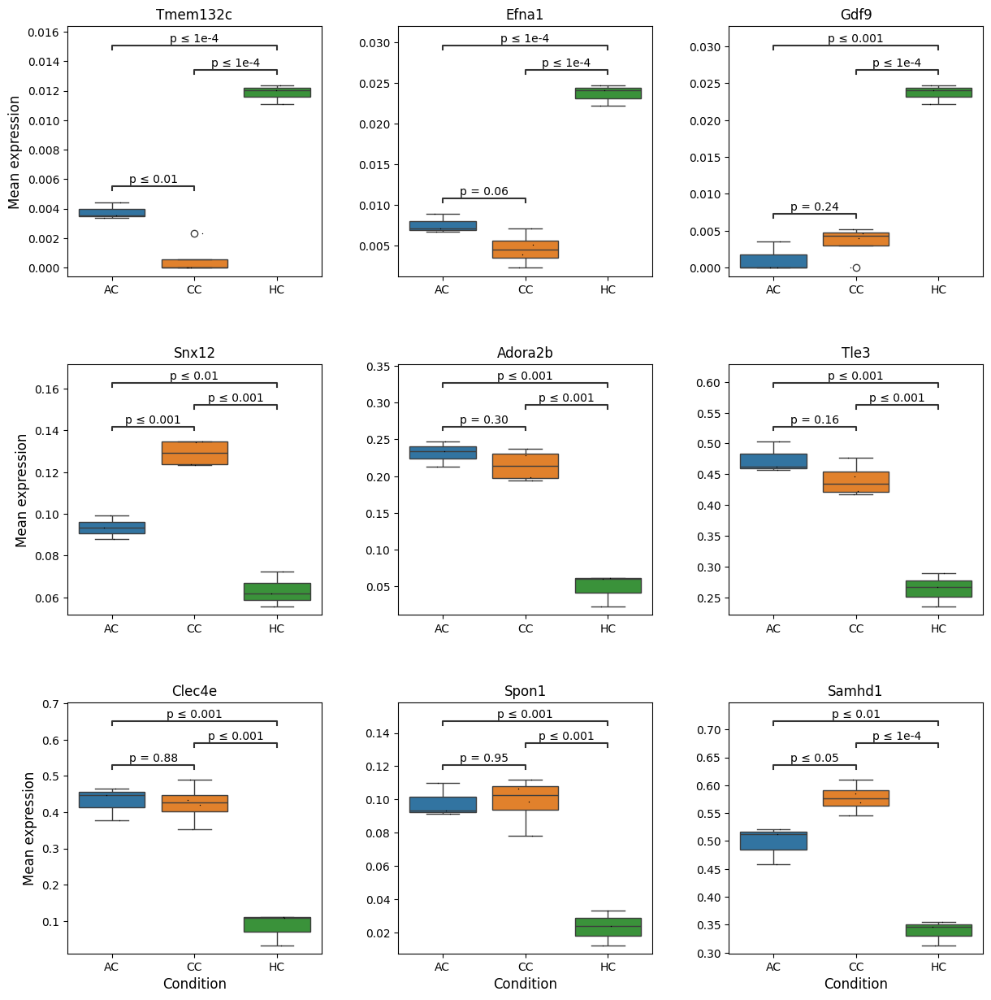

In [ ]:
## Show the first 9 genes
num_items_to_plot = 9
items_to_plot = df_res.iloc[:num_items_to_plot].index.values.tolist()

plot_pct_box( df_all[items_to_plot], df_all['Group'],
              ylabel = 'Mean expression', ncols = 3, figsize = (4,4), dpi = 100,
              title = None, title_y_pos = 1.05, title_fs = 14,
              label_fs = 12, tick_fs = 10, xtick_rot = 0, xtick_ha = 'center',
              annot_ref = None, annot_fmt = 'simple', annot_fs = 10,
              ws_hs = (0.3, 0.35), stripplot = True)

#### __D.6 Statistical test for mean-expression of some selected genes__


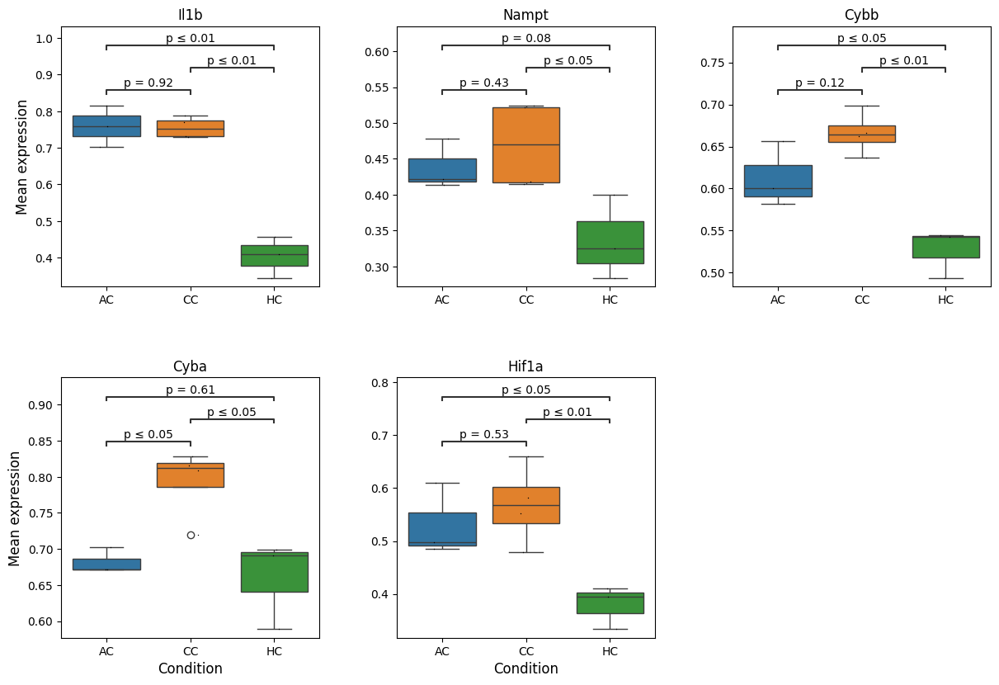

In [ ]:
items_to_plot = ['Il1b', 'Nampt', 'Cybb', 'Cyba', 'Hif1a']

plot_pct_box( df_all[items_to_plot], df_all['Group'],
              ylabel = 'Mean expression', ncols = 3, figsize = (4,4), dpi = 100,
              title = None, title_y_pos = 1.05, title_fs = 14,
              label_fs = 12, tick_fs = 10, xtick_rot = 0, xtick_ha = 'center',
              annot_ref = None, annot_fmt = 'simple', annot_fs = 10,
              ws_hs = (0.3, 0.35), stripplot = True)

### __E. Gene Set Aanalysis results__
- __GSEApy:__ https://github.com/zqfang/GSEApy

#### __E.1 Structure and format of the GSA/GSEA results__

In [ ]:
gsa_res_up = adata_t.uns['GSA_vs_ref_up']
gsa_res_dn = adata_t.uns['GSA_vs_ref_down']

list(gsa_res_up.keys())

['B cell',
 'Endothelial cell',
 'Epithelial cell',
 'Fibroblast',
 'ILC',
 'Macrophage',
 'Plasma cell',
 'Smooth muscle cell',
 'T cell CD4+']

##### __Structure of the GSA/GSEA results__

<div>
<img src="https://drive.google.com/uc?export=view&id=1RrmkpkWCI1rcfW5cIBfKvip-lX3lkJRL" align="center" width="500"/>
</div>

<div>
<img src=attachment:1369afc9-25a8-4811-bc55-41e7c61309af.png width="500"/>   
</div>

- The GSA/GSEA results are processed and stored separately for each cell type.
- The results were based on the corresponding DEG results.

In [ ]:
gsa_res = gsa_res_up
target_cell = 'Macrophage'

gsa_keys = list(gsa_res[target_cell].keys())
list(gsa_keys)

['AC_vs_HC', 'CC_vs_HC', 'HC_vs_others']

##### __Format of a GSA result__

In [ ]:
gsa_res[target_cell][gsa_keys[2]].head()

,pval,pval_adj,genes,overlap,pw_size,-log(p-val),-log(q-val),Term,Ind
AGE-RAGE signaling pathway in diabetic complications,1.326568e-07,0.00273,Vegfb;Col3a1;Col1a1;Col1a2;F3;Edn1;Vcam1;Plcb4...,16,101,6.877270,2.563783,AGE-RAGE signaling pathway in diabetic complic...,1
AMPK signaling pathway,5.008663e-02,1.00000,Sirt1;Irs2;Cd36;Creb5;Igf1;Ccnd1;Rheb;Eef2k,8,126,1.300278,0.000000,AMPK signaling pathway,1
Adherens junction,8.117439e-02,1.00000,Baiap2;Tgfbr1;Acp1;Tgfbr2;Src,5,72,1.090581,0.000000,Adherens junction,1
Amino sugar and nucleotide sugar metabolism,4.602458e-03,1.00000,Gnpnat1;Gmds;Pmm1;Nans;Npl;Hexb,6,49,2.337010,0.000000,Amino sugar and nucleotide sugar metabolism,1
Amoebiasis,5.967677e-04,1.00000,Col1a1;Col3a1;Serpinb6a;Hspb1;Plcb4;Serpinb1a;...,11,106,3.224195,0.000000,Amoebiasis,1


#### __E.2 Barplot visualization of condition-specific pathways activity__

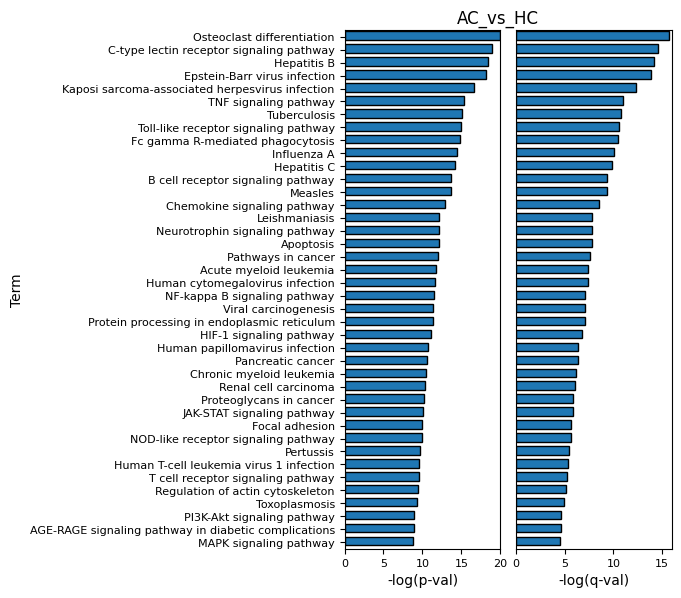

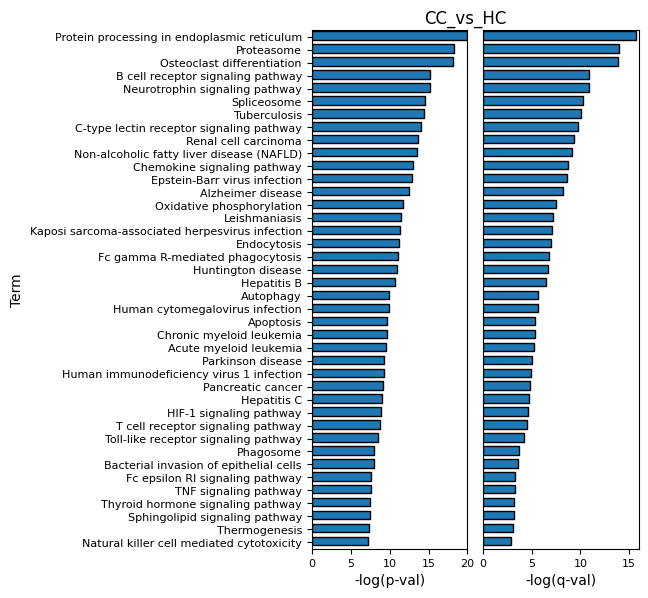

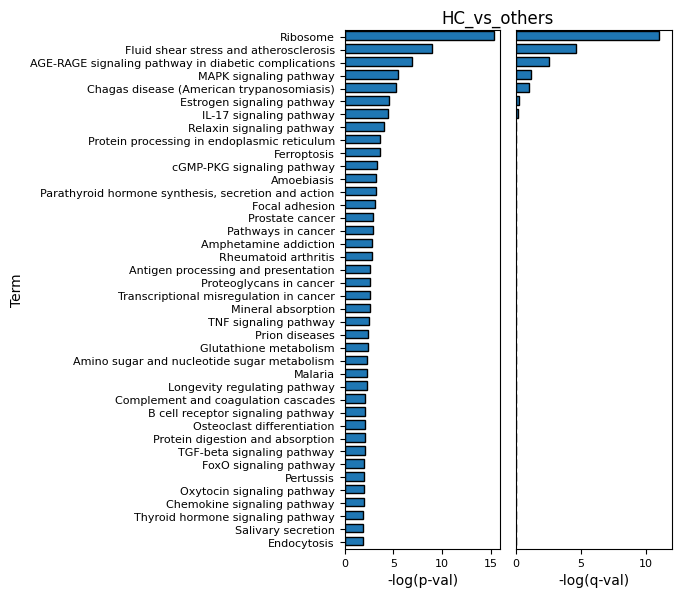

In [ ]:
target_cell = 'Macrophage'

df_gsa_dct = gsa_res[target_cell]

df_sel_dct = plot_gsa_bar( df_gsa_dct, pval_cutoff = 0.05, N_max_to_show = 40,
                           title = None, bar_width = 0.8,
                           title_pos = (0.5, 1), title_fs = 12, title_ha = 'center',
                           label_fs = 10, tick_fs = 8, wspace=0.1, hspace=0.25, Ax = None,
                           facecolor = 'tab:blue', edgecolor = 'black' )

#### __E.3 Dotplot visualization for an overview of condition-specific pathways activity__

In [ ]:
gsa_res = adata_t.uns['GSA_vs_ref_up']
gsa_res.keys()

dict_keys(['B cell', 'Endothelial cell', 'Epithelial cell', 'Fibroblast', 'ILC', 'Macrophage', 'Plasma cell', 'Smooth muscle cell', 'T cell CD4+'])

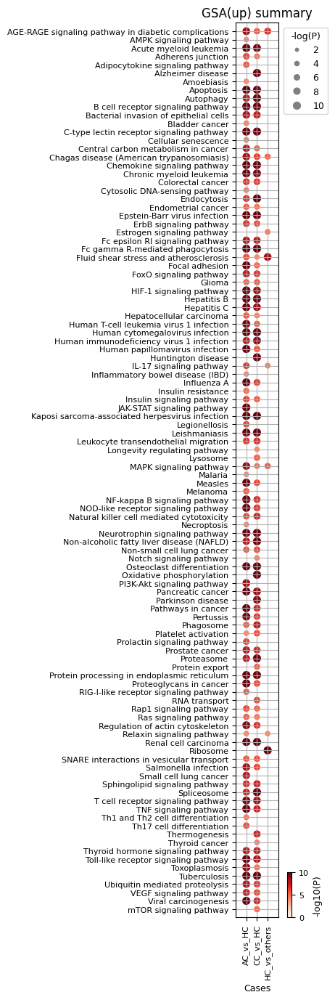

In [ ]:
key = 'Macrophage'
gsa_res_t = gsa_res[key]

plot_gsa_dot( gsa_res_t, pval_cutoff = 1e-4, title = 'GSA(up) summary', title_fs = 12,
              tick_fs = 8, xtick_rot = 90, xtick_ha = 'center',
              label_fs = 9, legend_fs = 9, swap_ax = False, figsize = (1,16),
              dpi = 100, dot_size = 50, cbar_frac = 0.1, cbar_aspect = 10, cmap = 'Reds' )

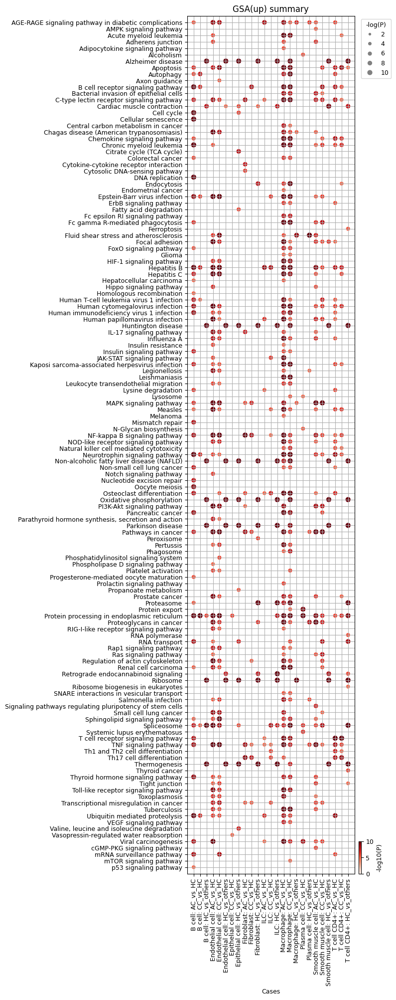

In [ ]:
plot_gsa_dot( gsa_res, pval_cutoff = 1e-5, title = 'GSA(up) summary',
              title_fs = 12, tick_fs = 9, xtick_rot = 90, xtick_ha = 'center',
              label_fs = 9, legend_fs = 9, swap_ax = False, figsize = None,
              dpi = 100, dot_size = 40, cbar_frac = 0.05, cbar_aspect = 15,
              cmap = 'Reds' )

### __F. GSEA results__
#### Data structure and format are the same as those for GSA results

In [ ]:
gsea_res = adata_t.uns['GSEA_vs_ref']
list(gsea_res.keys())

['B cell',
 'Endothelial cell',
 'Epithelial cell',
 'Fibroblast',
 'ILC',
 'Macrophage',
 'Plasma cell',
 'Smooth muscle cell',
 'T cell CD4+']

In [ ]:
target_cell = 'Macrophage'

gsea_keys = list(gsea_res[target_cell].keys())
list(gsea_keys)

['AC_vs_HC', 'CC_vs_HC', 'HC_vs_others']

#### __F.1 Barplot visualization of condition-specific pathways activity__

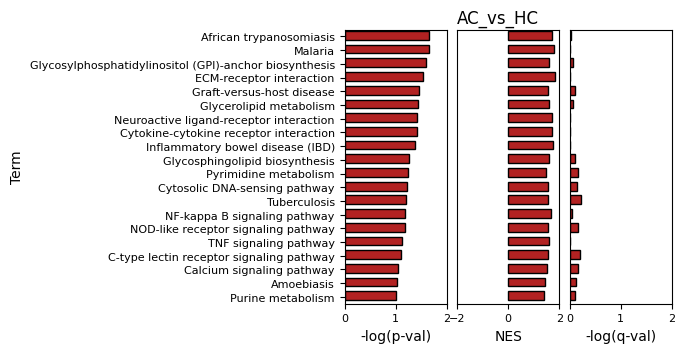

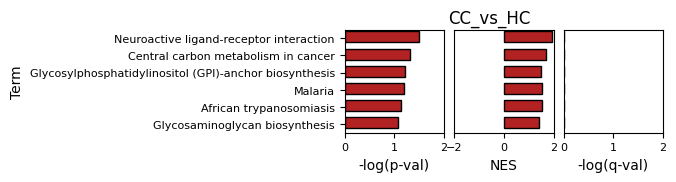

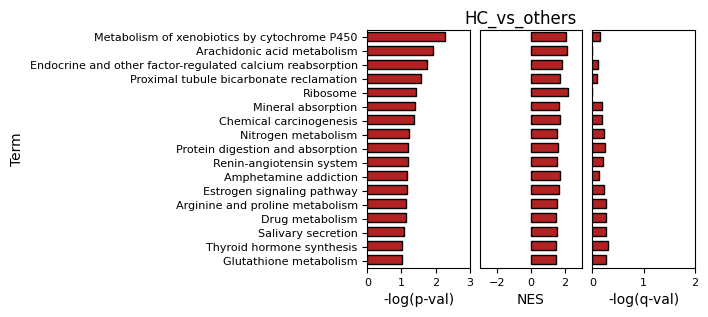

In [ ]:
target_cell = 'Macrophage'
# target_cell = 'Aneuploid Epithelial cell'
df_gsea_dct = gsea_res[target_cell]

df_sel_dct = plot_gsa_bar( df_gsea_dct, pval_cutoff = 1e-1,
                           nes_cutoff = 0, N_max_to_show = 50,
                           title = None, bar_width = 0.8,
                           title_pos = (0.5, 1), title_fs = 12, title_ha = 'center',
                           label_fs = 10, tick_fs = 8, wspace=0.1, hspace=0.25, Ax = None,
                           facecolor = 'firebrick', edgecolor = 'black' )

#### __F.2 Dotplot visualization for an overview of condition-specific pathways activity__

In [ ]:
gsea_res.keys()

dict_keys(['B cell', 'Endothelial cell', 'Epithelial cell', 'Fibroblast', 'ILC', 'Macrophage', 'Plasma cell', 'Smooth muscle cell', 'T cell CD4+'])

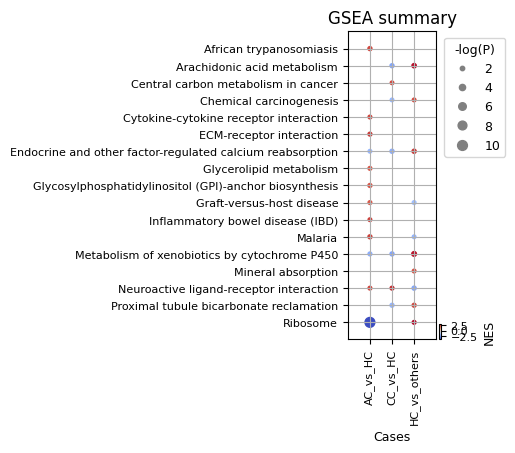

In [ ]:
# target_cell = 'Aneuploid Epithelial cell'
target_cell = 'Macrophage'

gsea_res_t = gsea_res['Macrophage']
pval_cutoff = 0.05

plot_gsa_dot( gsea_res_t, pval_cutoff = pval_cutoff,
              title = 'GSEA summary', title_fs = 12,
              tick_fs = 8, xtick_rot = 90, xtick_ha = 'center',
              label_fs = 9, legend_fs = 9, swap_ax = False, figsize = (1.2,4),
              dpi = 100, dot_size = 50, cbar_frac = 0.1, cbar_aspect = 10,
              cmap = 'coolwarm' )

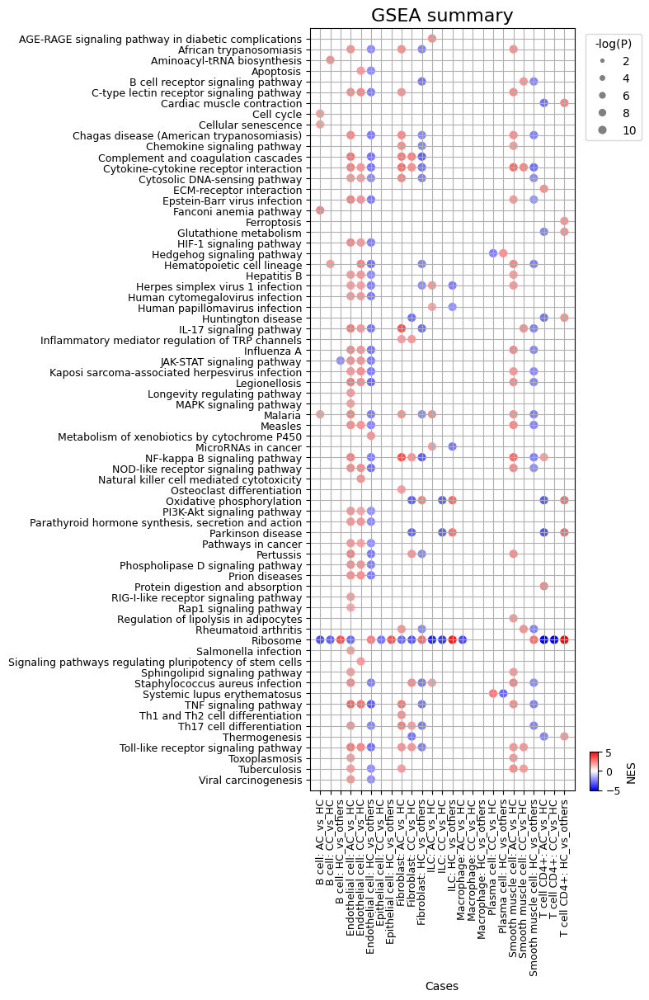

In [ ]:
plot_gsa_dot( gsea_res, pval_cutoff = 1e-4,
              title = 'GSEA summary', title_fs = 16,
              tick_fs = 9, xtick_rot = 90, xtick_ha = 'center',
              label_fs = 10, legend_fs = 10, swap_ax = False,
              figsize = None, dpi = 100, dot_size = 40,
              cbar_frac = 0.2, cbar_aspect = 5, cmap = 'bwr' )